100495850 - Arturo Hernanz

# Importar y gestionar el fichero de datos para poder generar el modelo

In [1]:
# Tratamiento de datos
# ==============================================================================
import numpy as np
import pandas as pd

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib import style
style.use('ggplot') or plt.style.use('ggplot')
import seaborn as sns
import math

# Preprocesado y modelado
# ==============================================================================
from sklearn.cluster import KMeans
from sklearn.preprocessing import scale
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import cophenet
from scipy.spatial.distance import pdist

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from scipy.stats import entropy
from collections import Counter



# Configuración warnings
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

datos = pd.read_csv("semillas.csv")
X = datos.drop(columns='clase')
y = datos['clase']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.33, random_state=100495850)

# Comparación de escaladores:

Vamos a comprobar, mediante comparación visual, cual de los siguientes escaladores separa mejor los datos: 
* RobustScaler()
* MinMaxScaler()
* StandarScaler()

## RobustScaler()

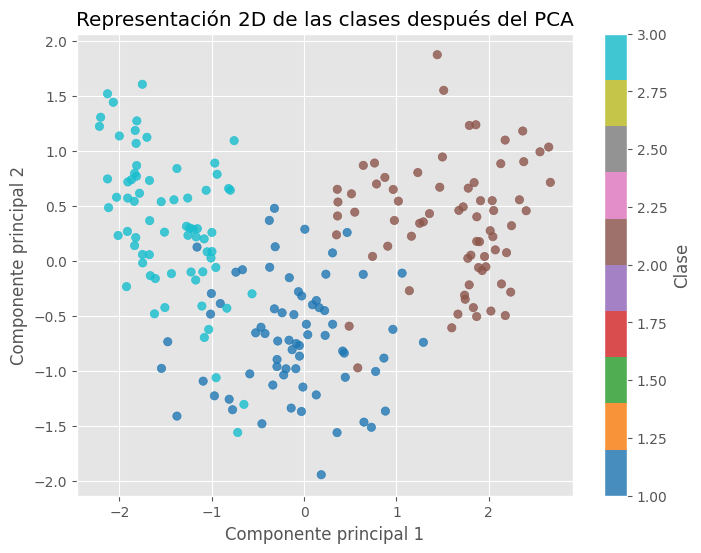

In [2]:
modelo_robust = Pipeline(steps=[
    ('escalador', RobustScaler()),
    ('pca', PCA(n_components=2)),
])

X_robust = modelo_robust.fit_transform(X)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_robust[:, 0], X_robust[:, 1], c=y, cmap='tab10', alpha=0.8)

plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.title('Representación 2D de las clases después del PCA')
plt.colorbar(scatter, label='Clase')
plt.grid(True)
plt.show()

Calculamos la varianza acumulada

In [3]:
varianza_explicada_robust = modelo_robust.named_steps['pca'].explained_variance_ratio_
varianza_acumulada_robust = varianza_explicada_robust.cumsum()

print("Varianza explicada por cada componente:")
print(varianza_explicada_robust)

print("\nVarianza explicada acumulada:")
print(varianza_acumulada_robust)

Varianza explicada por cada componente:
[0.66945748 0.19962637]

Varianza explicada acumulada:
[0.66945748 0.86908385]


Como podemos ver, la primera componente retiene el 66.94% de la información, mientras que la segunda el 19.96%. 
Usando ambas componentes mantenemos el 86.9% de la información.

## MinMaxScaler()

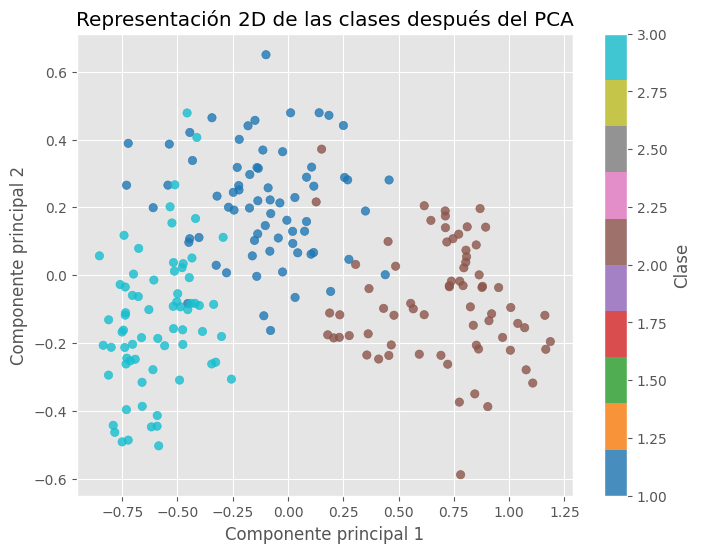

In [4]:
modelo_minmax = Pipeline(steps=[
    ('escalador', MinMaxScaler()),
    ('pca', PCA(n_components=2)),
])

X_minmax = modelo_minmax.fit_transform(X)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_minmax[:, 0], X_minmax[:, 1], c=y, cmap='tab10', alpha=0.8)

plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.title('Representación 2D de las clases después del PCA')
plt.colorbar(scatter, label='Clase')
plt.grid(True)
plt.show()

Calculamos la varianza acumulada

In [5]:
varianza_explicada_minmax = modelo_minmax.named_steps['pca'].explained_variance_ratio_
varianza_acumulada_minmax = varianza_explicada_minmax.cumsum()

print("Varianza explicada por cada componente:")
print(varianza_explicada_minmax)

print("\nVarianza explicada acumulada:")
print(varianza_acumulada_minmax)

Varianza explicada por cada componente:
[0.78903362 0.1290949 ]

Varianza explicada acumulada:
[0.78903362 0.91812852]


Como podemos ver, la primera componente retiene el 78.9% de la información, mientras que la segunda el 12.9%. 
Usando ambas componentes mantenemos el 91.81% de la información.

## StandardScaler()

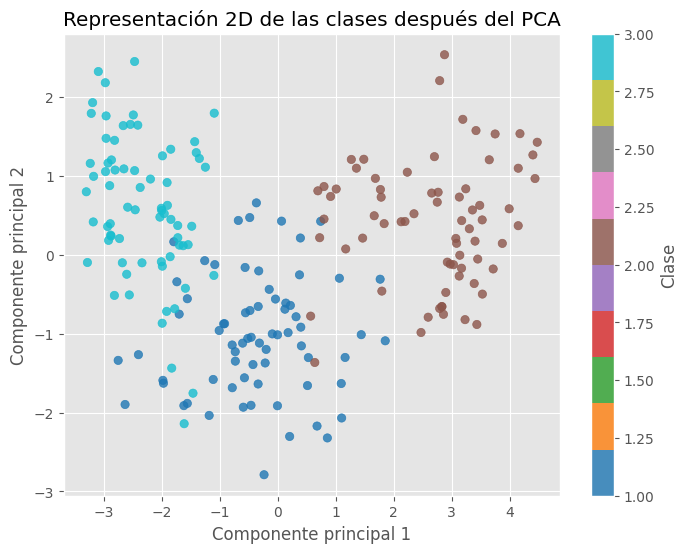

In [6]:
modelo_standar = Pipeline(steps=[
    ('escalador', StandardScaler()),
    ('pca', PCA(n_components=2)),  
])

X_standard = modelo_standar.fit_transform(X)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_standard[:, 0], X_standard[:, 1], c=y, cmap='tab10', alpha=0.8)

plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.title('Representación 2D de las clases después del PCA')
plt.colorbar(scatter, label='Clase')
plt.grid(True)
plt.show()

Calculamos la varianza acumulada

In [7]:
varianza_explicada_standard = modelo_standar.named_steps['pca'].explained_variance_ratio_
varianza_acumulada_standard = varianza_explicada_standard.cumsum()

print("Varianza explicada por cada componente:")
print(varianza_explicada_standard)

print("\nVarianza explicada acumulada:")
print(varianza_acumulada_standard)

Varianza explicada por cada componente:
[0.71874303 0.17108184]

Varianza explicada acumulada:
[0.71874303 0.88982486]


Como podemos ver, la primera componente retiene el 71.87%% de la información, mientras que la segunda el 17.1%. 
Usando ambas componentes mantenemos el 88.98% de la información.

## Resultado:

Habiendo dado los mejores resultados de varianza explicada (91.81 %) así como una comparación visual de la distribución de las clases similar, considero que el mejor escalador es MinMax

# Técnicas de Clustering:

En este apartado evaluaremos qué técnica de clustering de las vistas en clase (K-Means, Hierarchical Clustering o DBSCAN) da los mejores resultados, ajustando para ello sus hiperparámetros.

## K-Means

Para el modelo base elegimos 3 clusters, ya que, visualmente es lo que parece haber, así como un n_init alto para evitar obtener resultados subobtimos.

Evaluaremos que número de clusters es el mejor.

In [8]:
modelo_kmeans = KMeans(n_clusters=3, n_init = 25, random_state=100495850)
modelo_kmeans.fit(X_minmax)

KMeans(n_clusters=3, n_init=25, random_state=100495850)

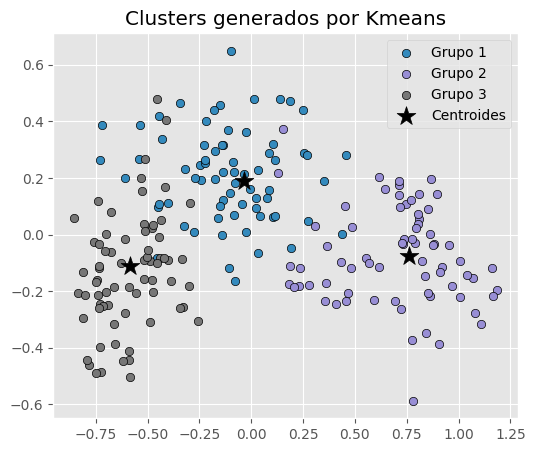

In [9]:
y_predict = modelo_kmeans.predict(X=X_minmax)
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
for i in np.unique(y):
    ax.scatter(
        x = X_minmax[y == i, 0],
        y = X_minmax[y == i, 1],
        c = plt.rcParams['axes.prop_cycle'].by_key()['color'][i],
        marker    = 'o',
        edgecolor = 'black',
        label= f"Grupo {i}"
    )

ax.scatter(
    x = modelo_kmeans.cluster_centers_[:, 0],
    y = modelo_kmeans.cluster_centers_[:, 1],
    c = 'black',
    s = 200,
    marker = '*',
    label  = 'Centroides'
)
ax.set_title('Clusters generados por Kmeans')
ax.legend();

Podemos ver que el resultado coincide con lo evaluado previamente, ahora ajustamos el número de clusters mediante la técnica del codo y silueta.

### Codo:

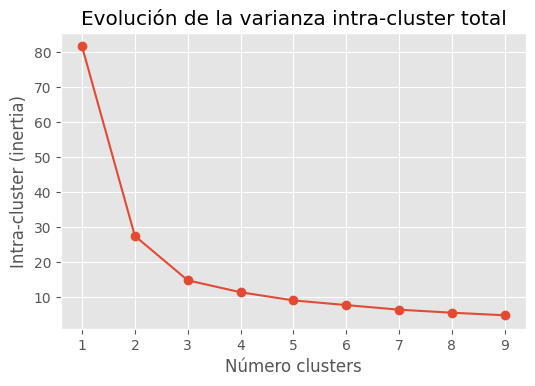

In [10]:
range_n_clusters = range(1, 10)
inertias = []

for n_clusters in range_n_clusters:
    modelo_kmeans = KMeans(
        n_clusters   = n_clusters,
        n_init       = 25,
        random_state = 100495850
    )
    modelo_kmeans.fit(X_minmax)
    inertias.append(modelo_kmeans.inertia_)

fig, ax = plt.subplots(1, 1, figsize=(6, 3.84))
ax.plot(range_n_clusters, inertias, marker='o')
ax.set_title("Evolución de la varianza intra-cluster total")
ax.set_xlabel('Número clusters')
ax.set_ylabel('Intra-cluster (inertia)');

Podemos ver que el número de clusters óptimo es 3, donde se encuentra el codo de la función.
En este caso el resultado se puede considerar poco claro (el 2 también podría considerarse codo), así que, nos apoyaremos en la técnica de silueta.

### Silueta:

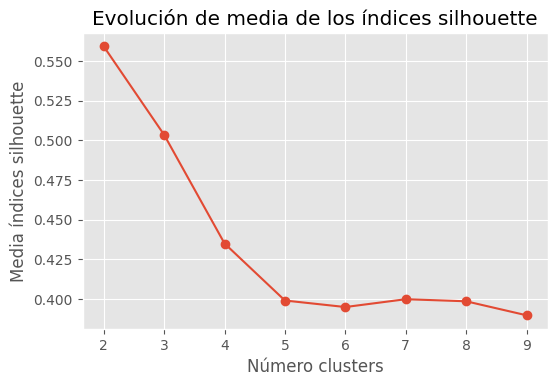

In [11]:
range_n_clusters = range(2, 10)
valores_medios_silhouette = []

for n_clusters in range_n_clusters:
    modelo_kmeans = KMeans(
        n_clusters   = n_clusters,
        n_init       = 25,
        random_state = 100495850
    )
    cluster_labels = modelo_kmeans.fit_predict(X_minmax)
    silhouette_avg = silhouette_score(X_minmax, cluster_labels)
    valores_medios_silhouette.append(silhouette_avg)

fig, ax = plt.subplots(1, 1, figsize=(6, 3.84))
ax.plot(range_n_clusters, valores_medios_silhouette, marker='o')
ax.set_title("Evolución de media de los índices silhouette")
ax.set_xlabel('Número clusters')
ax.set_ylabel('Media índices silhouette');

Para n_clusters = 2 La media de silhouette_score es : 0.55916224260137
Para n_clusters = 3 La media de silhouette_score es : 0.5031601414385409


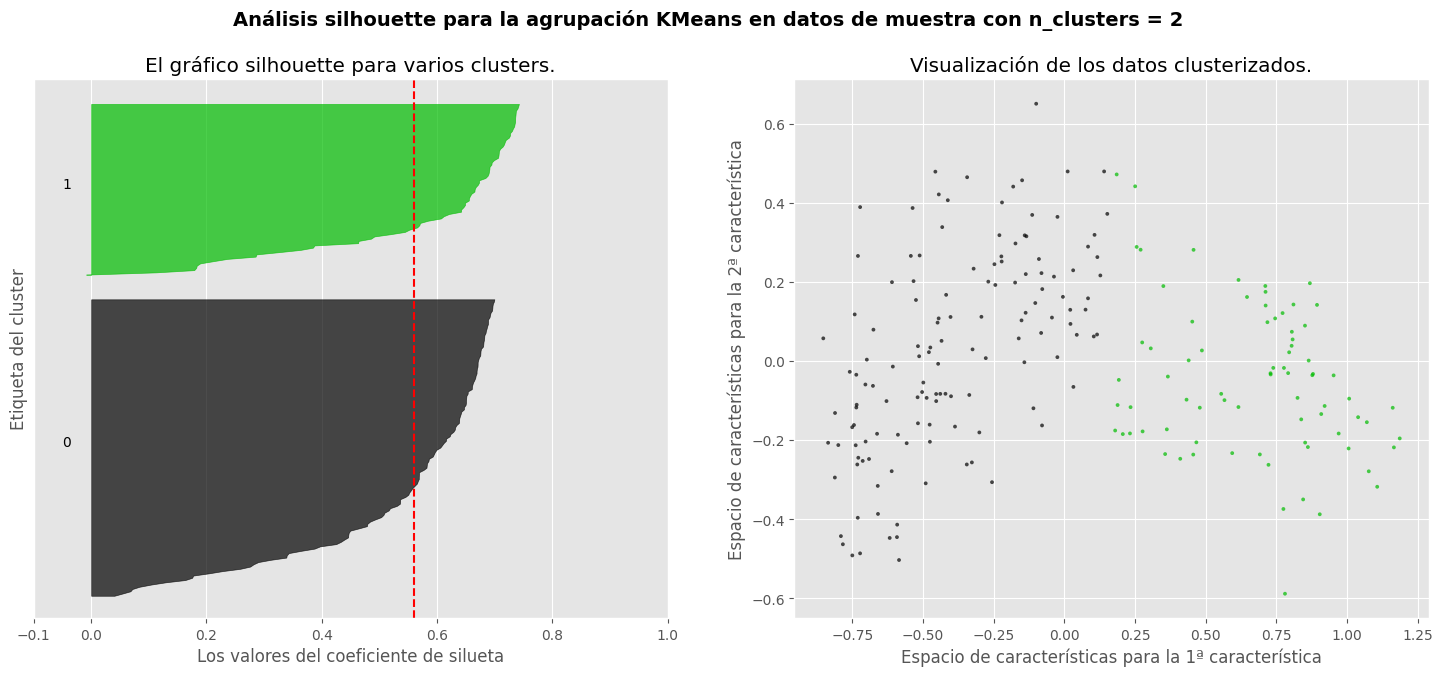

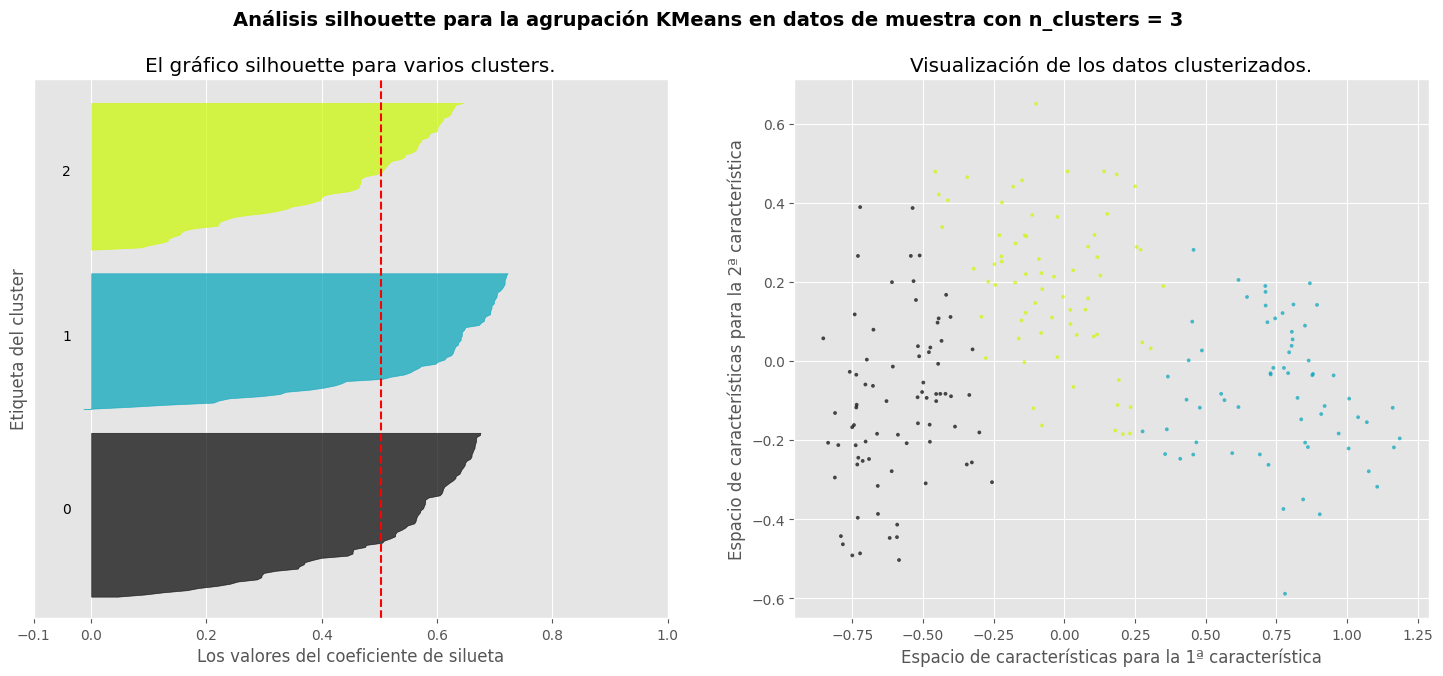

In [12]:
# Gráficos silhouette para identificar el número óptimo de clusters
# ==============================================================================

range_n_clusters = [2, 3]

for n_clusters in range_n_clusters:
    # Crear un subplot con 1 fila y dos columnas
    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    # El primer subplot es el gráfico silhouette
    # El coeficiente de silhouette puede oscilar entre -1, 1 pero en este ejemplo
    # todos se encuentran dentro de [-0.1, 1]
    ax1.set_xlim([-0.1, 1])
    # El (n_clusters+1)*10 sirve para insertar un espacio en blanco entre los
    # gráficos de silhouette de los clusters individuales, para delimitarlos claramente.
    ax1.set_ylim([0, len(X_minmax) + (n_clusters + 1) * 10])

    # Inicializar el clusterer con n_clusters valor y un generador aleatorio
    # aleatorio de 42 para la reproducibilidad.
    clusterer = KMeans(n_clusters=n_clusters, random_state=100495850)
    cluster_labels = clusterer.fit_predict(X_minmax)

    # El silhouette_score da el valor medio de todas las muestras. Esto da una
    # perspectiva de la densidad y separación de los clusters formados
    silhouette_avg = silhouette_score(X_minmax, cluster_labels)
    print(
        "Para n_clusters =",
        n_clusters,
        "La media de silhouette_score es :",
        silhouette_avg,
    )

    # Calcular las puntuaciones de silhouette de cada muestra
    sample_silhouette_values = silhouette_samples(X_minmax, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        # Agregar las puntuaciones de silhouette de las muestras pertenecientes al
        # cluster i, y ordénelas
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]

        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Etiquetar los gráficos de silhouette con sus números de cluster en el
        # centro.
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Calcular el nuevo y_lower para el siguiente gráfico
        y_lower = y_upper + 10

    ax1.set_title("El gráfico silhouette para varios clusters.")
    ax1.set_xlabel("Los valores del coeficiente de silueta")
    ax1.set_ylabel("Etiqueta del cluster")

    # La línea vertical para la puntuación media de silhouette de todos los valores
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([])
    ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    # El segundo plot dibuja los clusters formados
    colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
    ax2.scatter(
        X_minmax[:, 0], X_minmax[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k"
    )


    ax2.set_title("Visualización de los datos clusterizados.")
    ax2.set_xlabel("Espacio de características para la 1ª característica")
    ax2.set_ylabel("Espacio de características para la 2ª característica")

    plt.suptitle(
        "Análisis silhouette para la agrupación KMeans en datos de muestra con n_clusters = %d"
        % n_clusters,
        fontsize=14,
        fontweight="bold",
    )

plt.show()

### Resultado:

Efectivamente el mejor resultado es k = 3, ya que, como podemos ver en el gráfico de la silueta los grupos de muestras quedan más equilibrados, además, realmente no hay una perdida significativa de la media de silhouette_score respecto a k = 2.

In [13]:
modelo_kmeans_final = KMeans(
    n_clusters   = 3,
    n_init       = 25,
    random_state = 100495850
)
modelo_kmeans_final.fit(X=X_minmax)

KMeans(n_clusters=3, n_init=25, random_state=100495850)

## Hierarchical Clustering

Como modelos base voy a elegir uno por cada linkage visto en clase (complete, average y ward).

Evaluaremos que número de clusters y qué función son mejores.

In [14]:
modelo_hclust_complete = AgglomerativeClustering(
    linkage  = 'complete',
    distance_threshold = 0,
    n_clusters         = None,
    compute_distances  = True
)
modelo_hclust_complete.fit(X=X_minmax)

modelo_hclust_average = AgglomerativeClustering(
    linkage  = 'average',
    distance_threshold = 0,
    n_clusters         = None,
    compute_distances  = True
)
modelo_hclust_average.fit(X=X_minmax)

modelo_hclust_ward = AgglomerativeClustering(
    linkage  = 'ward',
    distance_threshold = 0,
    n_clusters         = None,
    compute_distances  = True
)
modelo_hclust_ward.fit(X=X_minmax)

AgglomerativeClustering(compute_distances=True, distance_threshold=0,
                        n_clusters=None)

Analizamos el número de clusters mediante dendogramas y silueta.

### Dendogramas:

Función auxiliar para extraer la información y dibujar dendogramas.

In [15]:
def plot_dendrogram(model, **kwargs):

    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack([model.children_, model.distances_,
                                      counts]).astype(float)

    # Plot
    dendrogram(linkage_matrix, **kwargs)

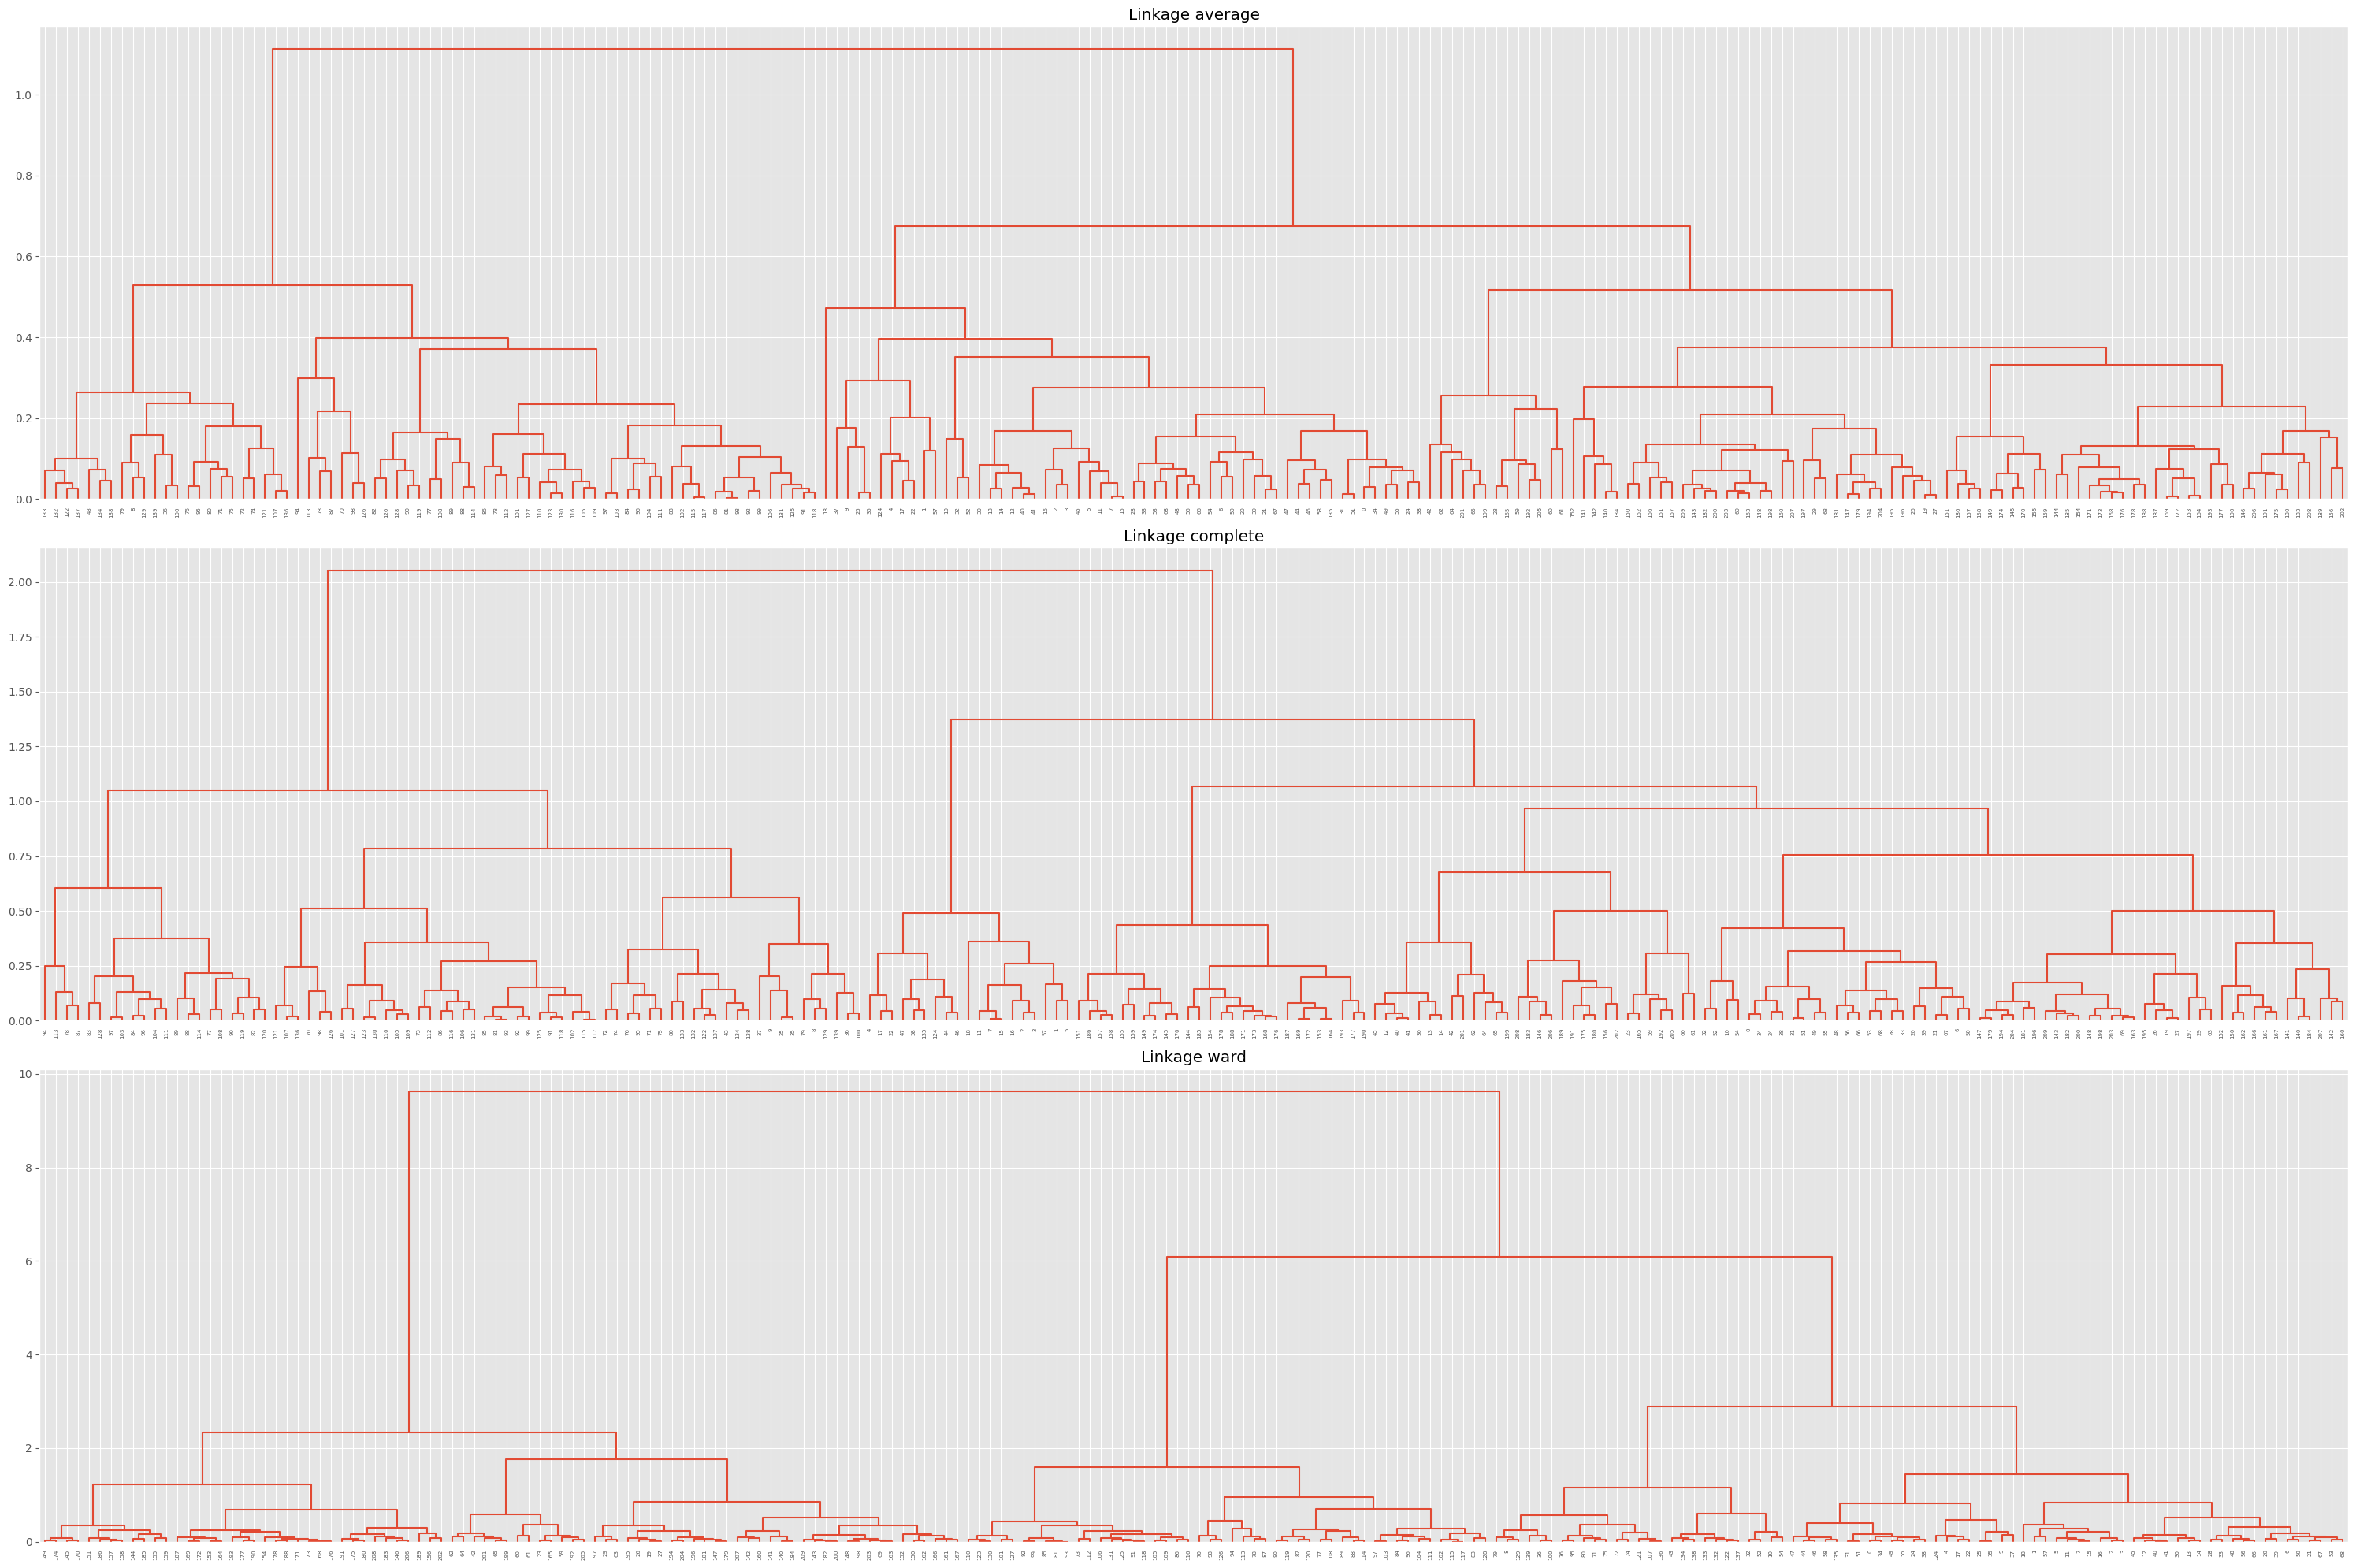

In [16]:
fig, axs = plt.subplots(3, 1, figsize=(30, 20))
datos_scaled = pd.DataFrame(X_minmax, index=X.index, columns=["PC1", "PC2"])
plot_dendrogram(modelo_hclust_average, labels=datos_scaled.index, color_threshold=0, ax=axs[0])
axs[0].set_title("Linkage average")
plot_dendrogram(modelo_hclust_complete, labels=datos_scaled.index, color_threshold=0, ax=axs[1])
axs[1].set_title("Linkage complete")
plot_dendrogram(modelo_hclust_ward, labels=datos_scaled.index, color_threshold=0, ax=axs[2])
axs[2].set_title("Linkage ward")
plt.tight_layout();

Analizamos las diferentes distancias de los dendogramas:

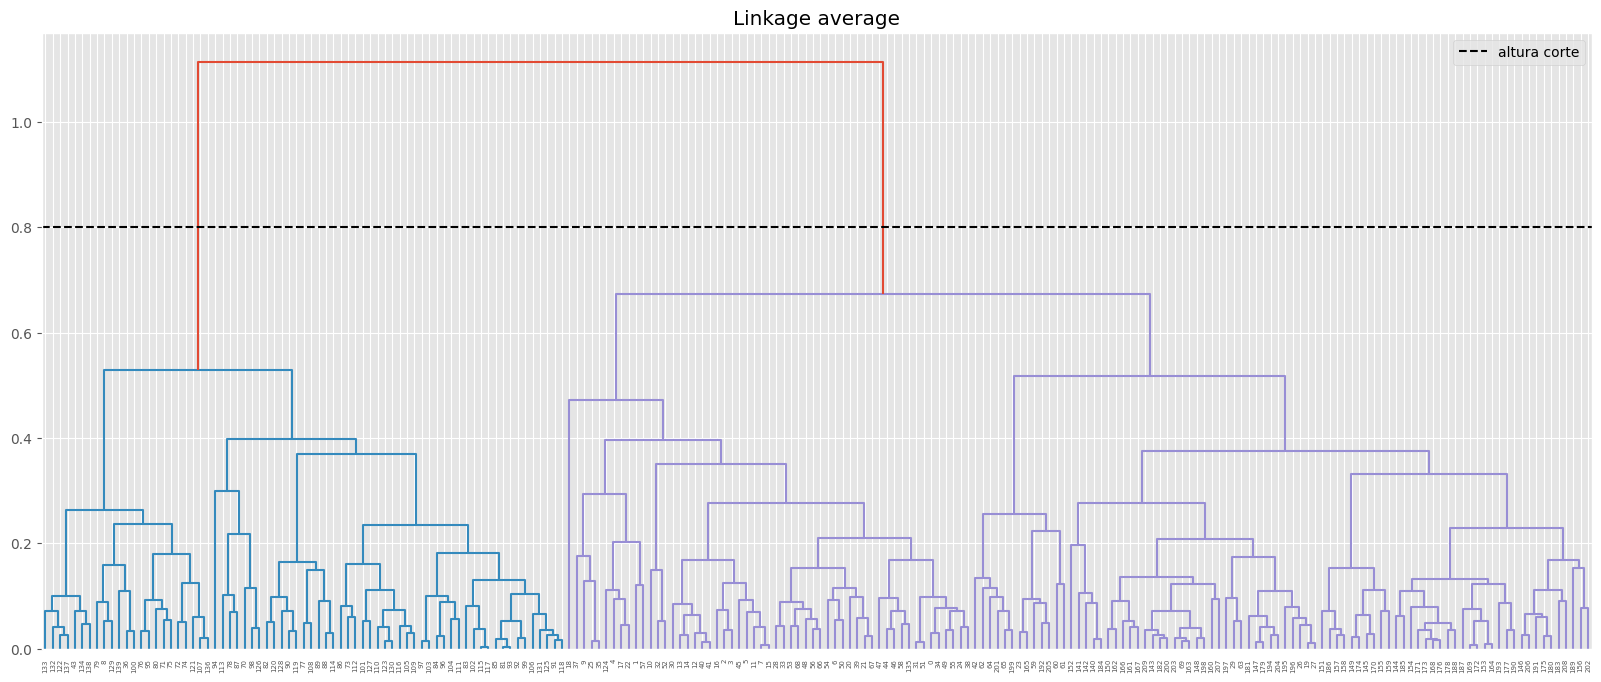

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(20, 8))
altura_corte = 0.8
plot_dendrogram(modelo_hclust_average, labels=datos_scaled.index, color_threshold=altura_corte, ax=ax)
ax.set_title("Linkage average")
ax.axhline(y=altura_corte, c = 'black', linestyle='--', label='altura corte')
ax.legend();

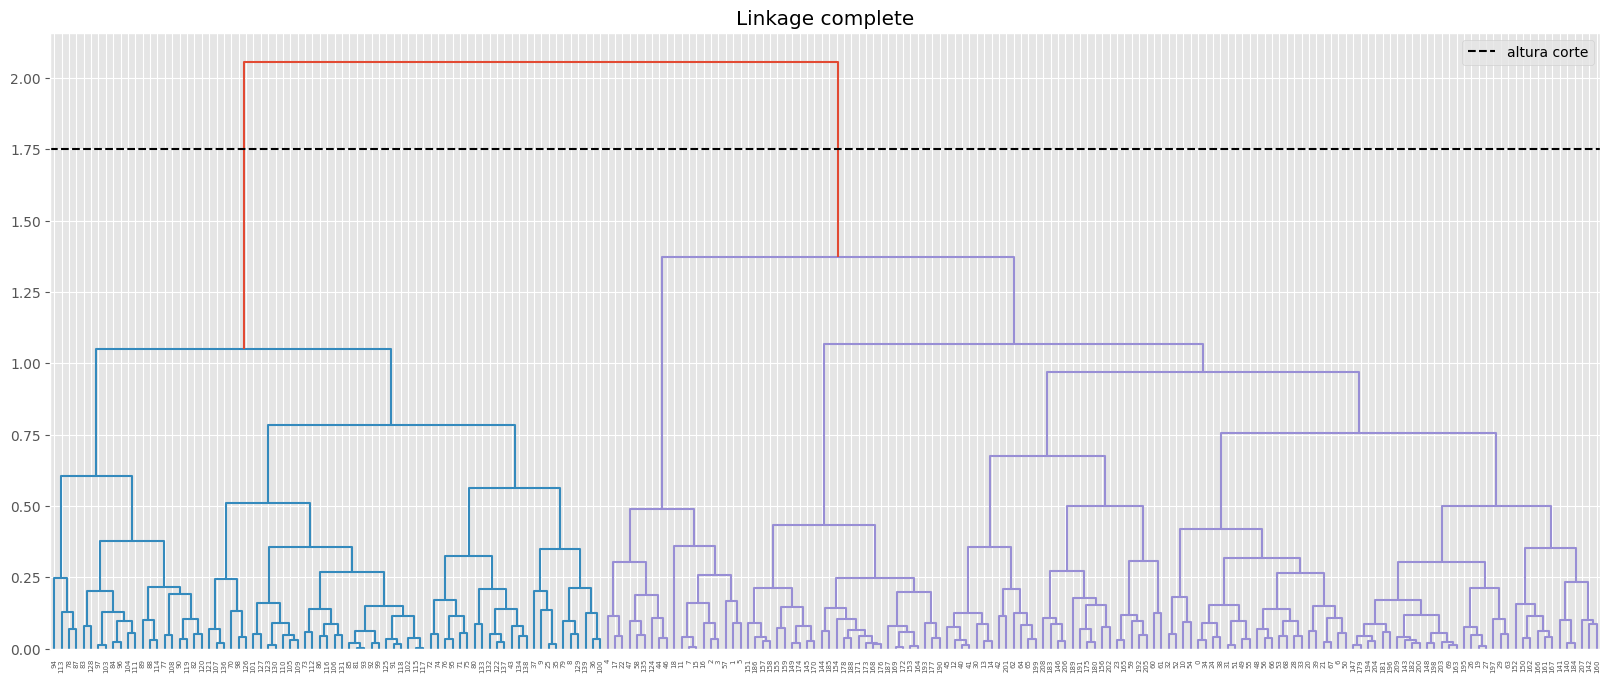

In [18]:
fig, ax = plt.subplots(1, 1, figsize=(20, 8))
altura_corte = 1.75
plot_dendrogram(modelo_hclust_complete, labels=datos_scaled.index, color_threshold=altura_corte, ax=ax)
ax.set_title("Linkage complete")
ax.axhline(y=altura_corte, c = 'black', linestyle='--', label='altura corte')
ax.legend();

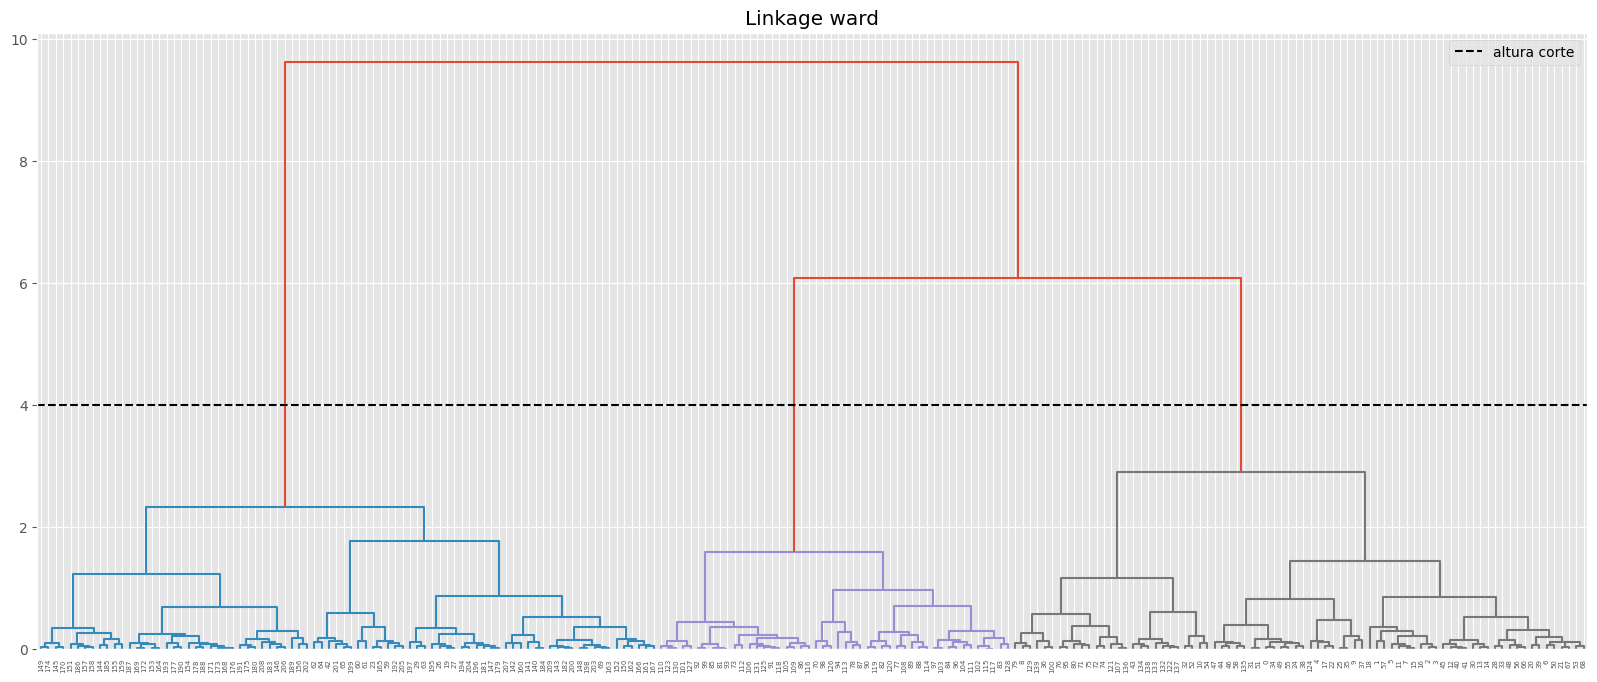

In [19]:
fig, ax = plt.subplots(1, 1, figsize=(20, 8))
altura_corte = 4
plot_dendrogram(modelo_hclust_ward, labels=datos_scaled.index, color_threshold=altura_corte, ax=ax)
ax.set_title("Linkage ward")
ax.axhline(y=altura_corte, c = 'black', linestyle='--', label='altura corte')
ax.legend();

Tanto para los linkage complete y average el mejor número de clusters es 2, mientras que para ward es 3, sin embargo, para confirmar esta hipótesis y decidir que valor vamos a elegir, analizaremos los índices silhouette:

### Silueta:

#### Linkage Average:

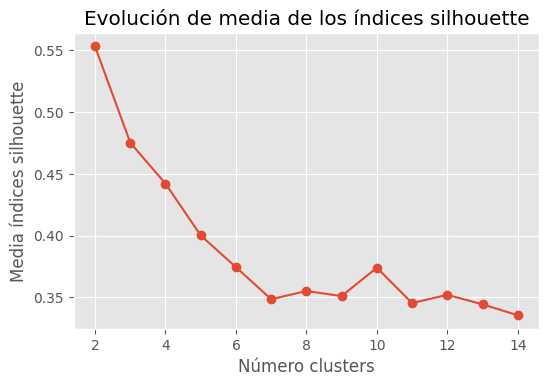

In [20]:
range_n_clusters = range(2, 15)
valores_medios_silhouette = []

for n_clusters in range_n_clusters:
    modelo = AgglomerativeClustering(
        linkage    = 'average',
        n_clusters = n_clusters
    )

    cluster_labels = modelo.fit_predict(X_minmax)
    silhouette_avg = silhouette_score(X_minmax, cluster_labels)
    valores_medios_silhouette.append(silhouette_avg)

fig, ax = plt.subplots(1, 1, figsize=(6, 3.84))
ax.plot(range_n_clusters, valores_medios_silhouette, marker='o')
ax.set_title("Evolución de media de los índices silhouette")
ax.set_xlabel('Número clusters')
ax.set_ylabel('Media índices silhouette');

Para n_clusters = 2 La media de silhouette_score es : 0.5531455550794524
Para n_clusters = 3 La media de silhouette_score es : 0.47520882333730075
Para n_clusters = 4 La media de silhouette_score es : 0.4420242885440925


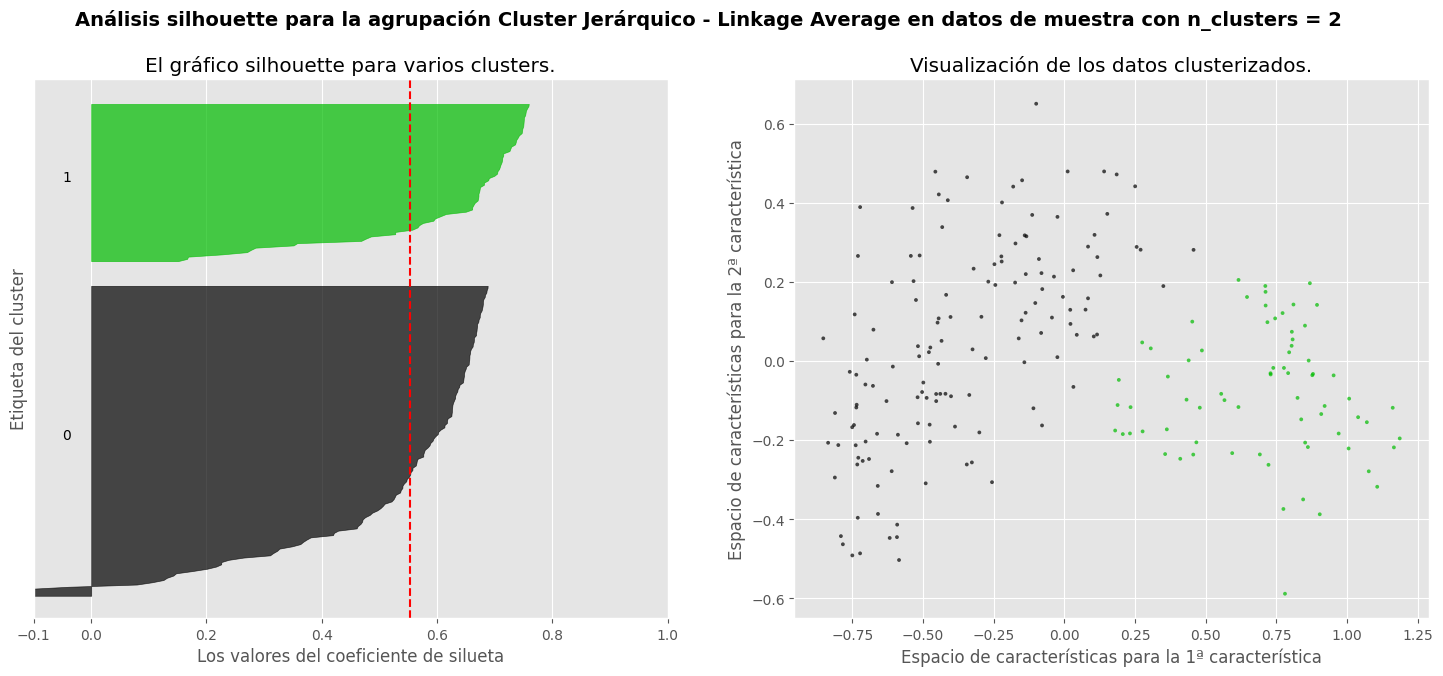

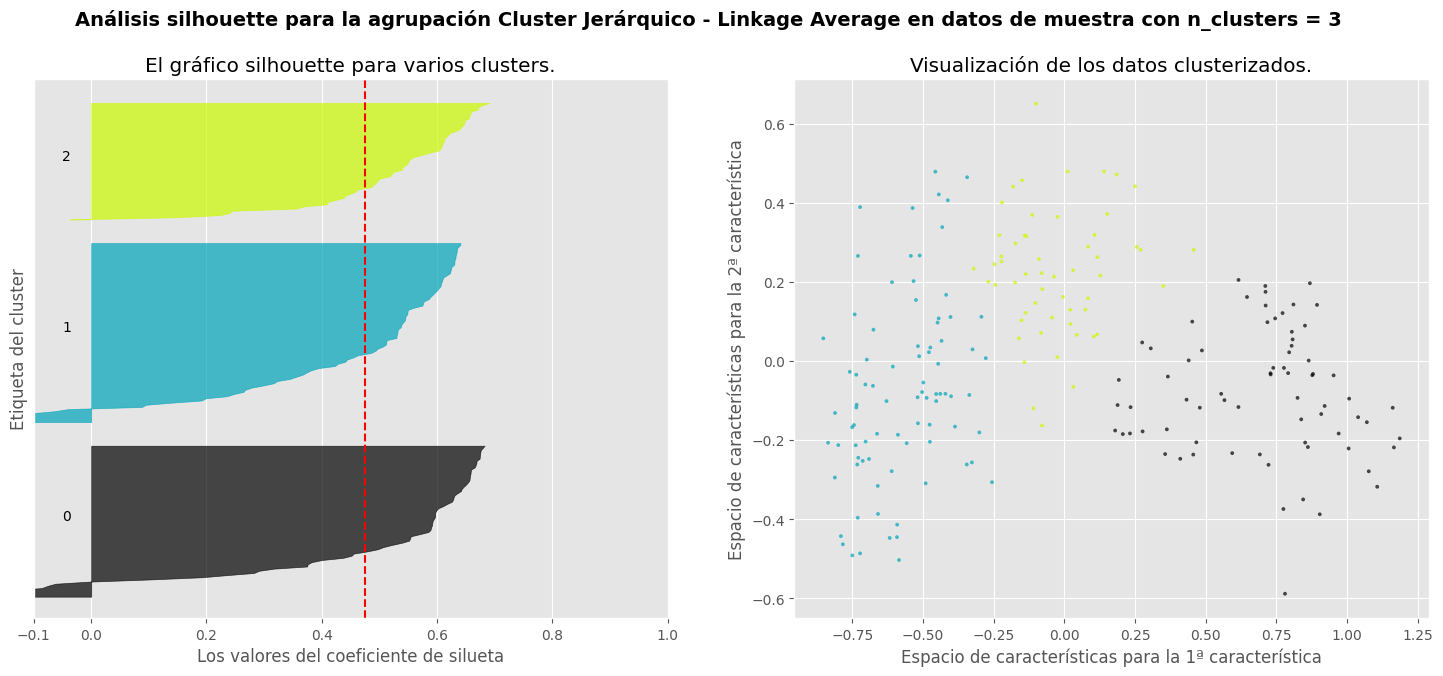

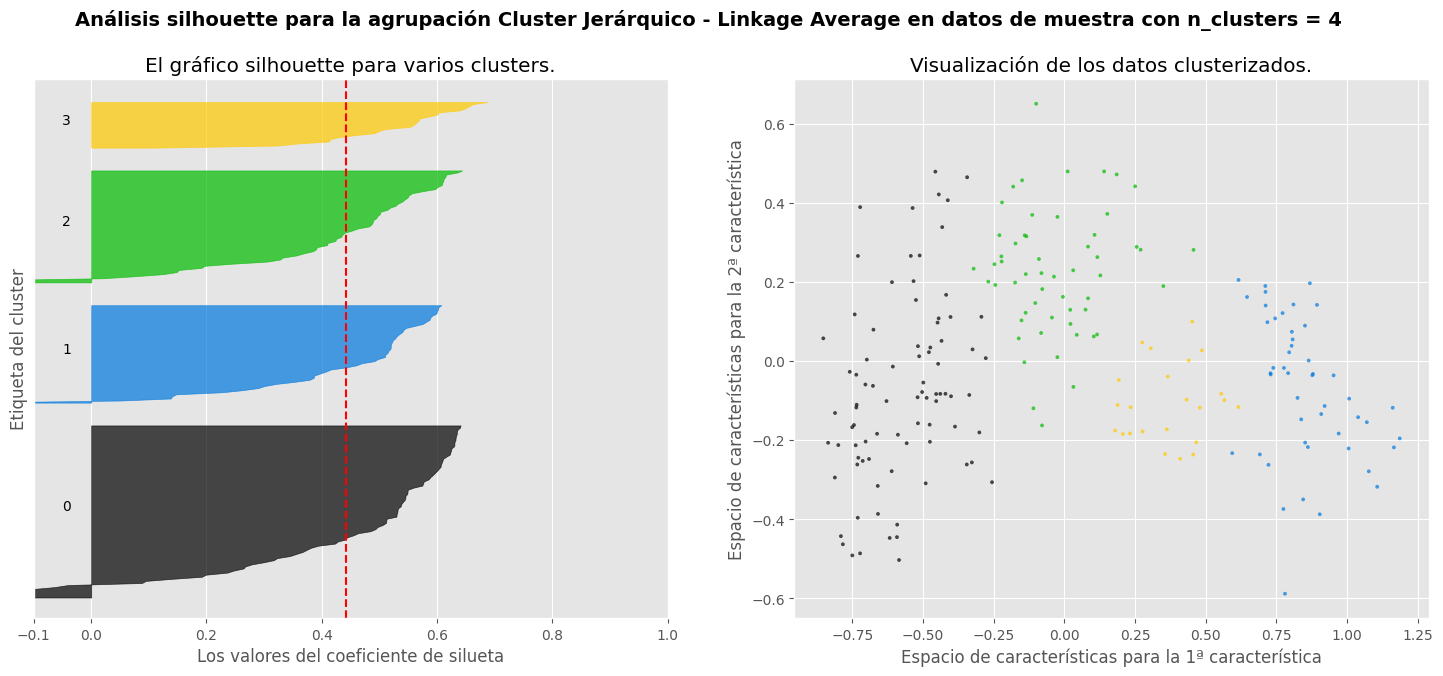

In [21]:
# Gráficos silhouette para identificar el número óptimo de clusters
# ==============================================================================

range_n_clusters = [2, 3, 4,]

for n_clusters in range_n_clusters:
    # Crear un subplot con 1 fila y dos columnas
    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    # El primer subplot es el gráfico silhouette
    # El coeficiente de silhouette puede oscilar entre -1, 1 pero en este ejemplo
    # todos se encuentran dentro de [-0.1, 1]
    ax1.set_xlim([-0.1, 1])
    # El (n_clusters+1)*10 sirve para insertar un espacio en blanco entre los
    # gráficos de silhouette de los clusters individuales, para delimitarlos claramente.
    ax1.set_ylim([0, len(X_minmax) + (n_clusters + 1) * 10])

    # Inicializar el clusterer con n_clusters valor y un generador aleatorio
    # aleatorio de 42 para la reproducibilidad.
    clusterer = AgglomerativeClustering(
        linkage    = 'average',
        n_clusters = n_clusters
    )
    cluster_labels = clusterer.fit_predict(X_minmax)

    # El silhouette_score da el valor medio de todas las muestras. Esto da una
    # perspectiva de la densidad y separación de los clusters formados
    silhouette_avg = silhouette_score(X_minmax, cluster_labels)
    print(
        "Para n_clusters =",
        n_clusters,
        "La media de silhouette_score es :",
        silhouette_avg,
    )

    # Calcular las puntuaciones de silhouette de cada muestra
    sample_silhouette_values = silhouette_samples(X_minmax, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        # Agregar las puntuaciones de silhouette de las muestras pertenecientes al
        # cluster i, y ordénelas
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]

        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Etiquetar los gráficos de silhouette con sus números de cluster en el
        # centro.
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Calcular el nuevo y_lower para el siguiente gráfico
        y_lower = y_upper + 10

    ax1.set_title("El gráfico silhouette para varios clusters.")
    ax1.set_xlabel("Los valores del coeficiente de silueta")
    ax1.set_ylabel("Etiqueta del cluster")

    # La línea vertical para la puntuación media de silhouette de todos los valores
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([])
    ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    # El segundo plot dibuja los clusters formados
    colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
    ax2.scatter(
        X_minmax[:, 0], X_minmax[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k"
    )


    ax2.set_title("Visualización de los datos clusterizados.")
    ax2.set_xlabel("Espacio de características para la 1ª característica")
    ax2.set_ylabel("Espacio de características para la 2ª característica")

    plt.suptitle(
        "Análisis silhouette para la agrupación Cluster Jerárquico - Linkage Average en datos de muestra con n_clusters = %d"
        % n_clusters,
        fontsize=14,
        fontweight="bold",
    )

plt.show()

Para el linkage average el mejor resultado son 2 clusters y una media de 0.55

#### Linkage Complete:

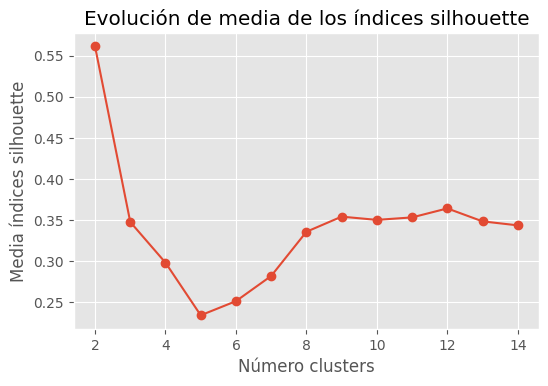

In [22]:
range_n_clusters = range(2, 15)
valores_medios_silhouette = []

for n_clusters in range_n_clusters:
    modelo = AgglomerativeClustering(
        linkage    = 'complete',
        n_clusters = n_clusters
    )

    cluster_labels = modelo.fit_predict(X_minmax)
    silhouette_avg = silhouette_score(X_minmax, cluster_labels)
    valores_medios_silhouette.append(silhouette_avg)

fig, ax = plt.subplots(1, 1, figsize=(6, 3.84))
ax.plot(range_n_clusters, valores_medios_silhouette, marker='o')
ax.set_title("Evolución de media de los índices silhouette")
ax.set_xlabel('Número clusters')
ax.set_ylabel('Media índices silhouette');

Para n_clusters = 2 La media de silhouette_score es : 0.5610155665238008
Para n_clusters = 3 La media de silhouette_score es : 0.3475372823442006
Para n_clusters = 4 La media de silhouette_score es : 0.2980428935617485


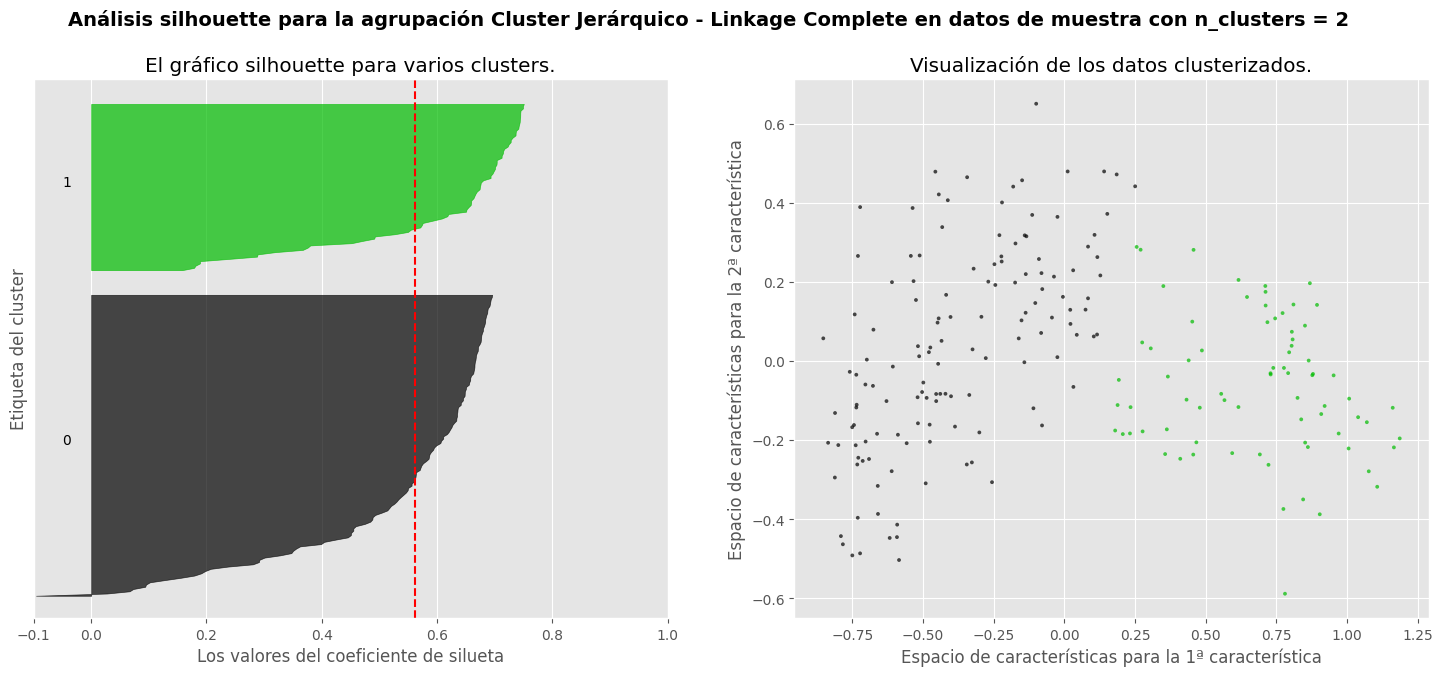

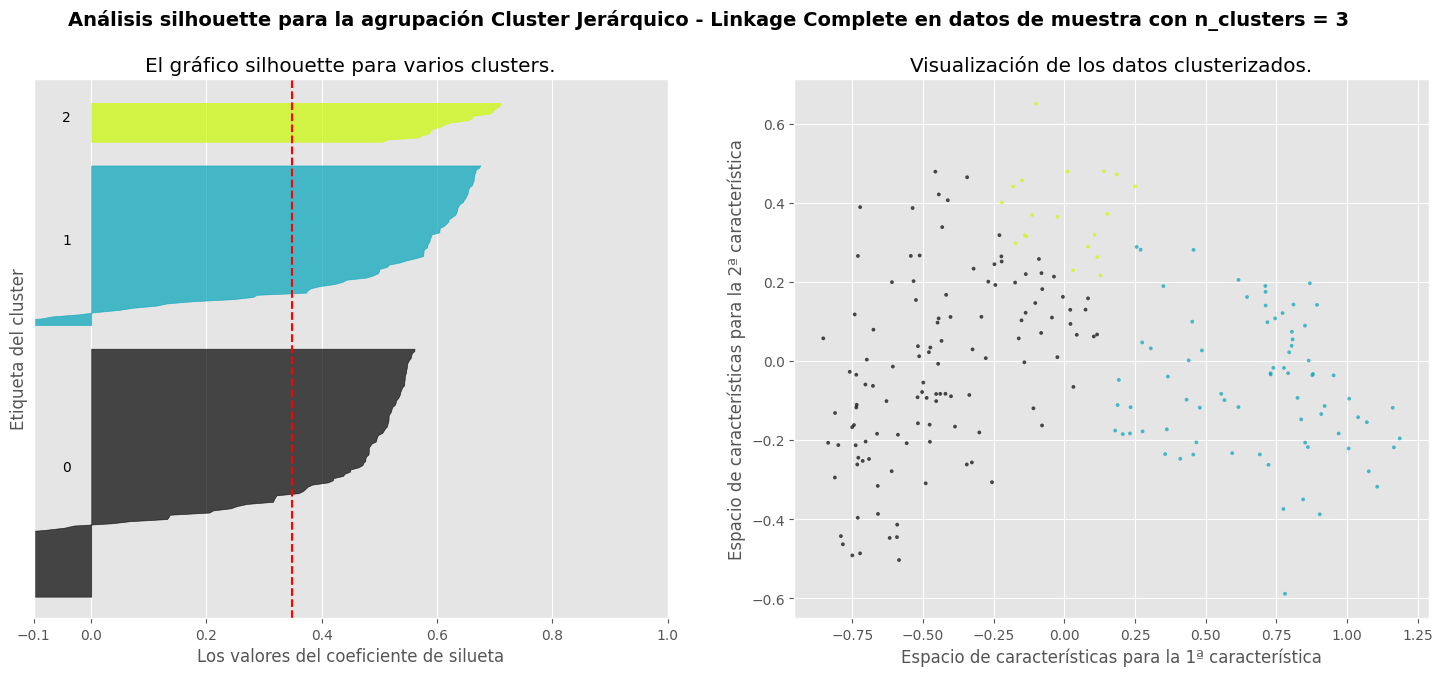

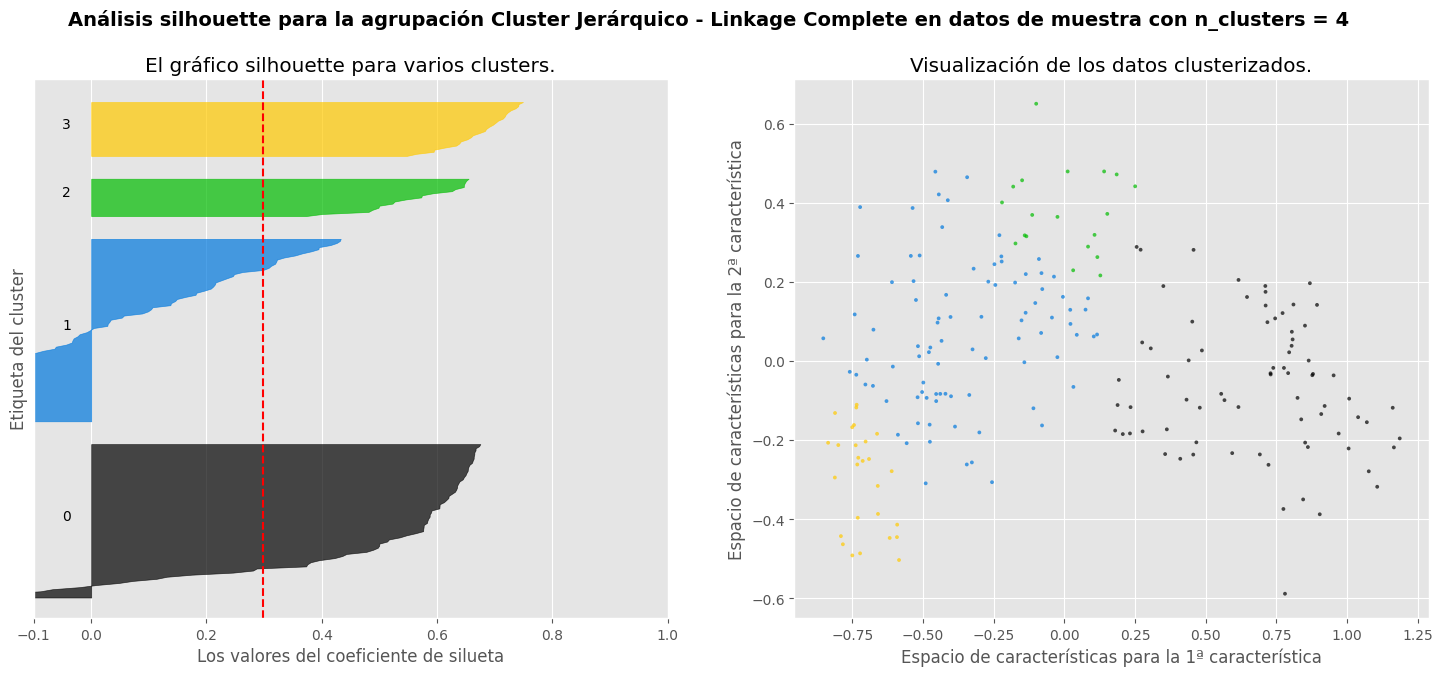

In [23]:
# Gráficos silhouette para identificar el número óptimo de clusters
# ==============================================================================

range_n_clusters = [2, 3, 4,]

for n_clusters in range_n_clusters:
    # Crear un subplot con 1 fila y dos columnas
    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    # El primer subplot es el gráfico silhouette
    # El coeficiente de silhouette puede oscilar entre -1, 1 pero en este ejemplo
    # todos se encuentran dentro de [-0.1, 1]
    ax1.set_xlim([-0.1, 1])
    # El (n_clusters+1)*10 sirve para insertar un espacio en blanco entre los
    # gráficos de silhouette de los clusters individuales, para delimitarlos claramente.
    ax1.set_ylim([0, len(X_minmax) + (n_clusters + 1) * 10])

    # Inicializar el clusterer con n_clusters valor y un generador aleatorio
    # aleatorio de 42 para la reproducibilidad.
    clusterer = AgglomerativeClustering(
        linkage    = 'complete',
        n_clusters = n_clusters
    )
    cluster_labels = clusterer.fit_predict(X_minmax)

    # El silhouette_score da el valor medio de todas las muestras. Esto da una
    # perspectiva de la densidad y separación de los clusters formados
    silhouette_avg = silhouette_score(X_minmax, cluster_labels)
    print(
        "Para n_clusters =",
        n_clusters,
        "La media de silhouette_score es :",
        silhouette_avg,
    )

    # Calcular las puntuaciones de silhouette de cada muestra
    sample_silhouette_values = silhouette_samples(X_minmax, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        # Agregar las puntuaciones de silhouette de las muestras pertenecientes al
        # cluster i, y ordénelas
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]

        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Etiquetar los gráficos de silhouette con sus números de cluster en el
        # centro.
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Calcular el nuevo y_lower para el siguiente gráfico
        y_lower = y_upper + 10

    ax1.set_title("El gráfico silhouette para varios clusters.")
    ax1.set_xlabel("Los valores del coeficiente de silueta")
    ax1.set_ylabel("Etiqueta del cluster")

    # La línea vertical para la puntuación media de silhouette de todos los valores
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([])
    ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    # El segundo plot dibuja los clusters formados
    colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
    ax2.scatter(
        X_minmax[:, 0], X_minmax[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k"
    )


    ax2.set_title("Visualización de los datos clusterizados.")
    ax2.set_xlabel("Espacio de características para la 1ª característica")
    ax2.set_ylabel("Espacio de características para la 2ª característica")

    plt.suptitle(
        "Análisis silhouette para la agrupación Cluster Jerárquico - Linkage Complete en datos de muestra con n_clusters = %d"
        % n_clusters,
        fontsize=14,
        fontweight="bold",
    )

plt.show()

Para el linkage complete el mejor resultado son 2 clusters y una media de 0.56

#### Linkage Ward

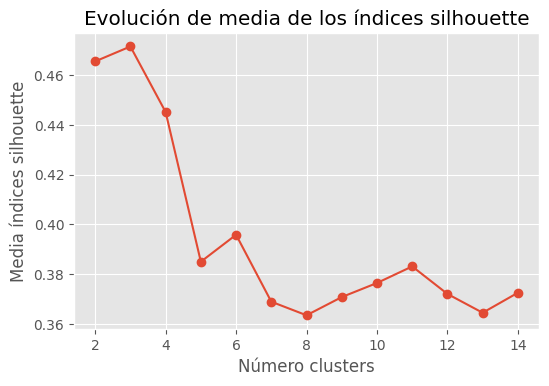

In [24]:
range_n_clusters = range(2, 15)
valores_medios_silhouette = []

for n_clusters in range_n_clusters:
    modelo = AgglomerativeClustering(
        linkage    = 'ward',
        n_clusters = n_clusters
    )

    cluster_labels = modelo.fit_predict(X_minmax)
    silhouette_avg = silhouette_score(X_minmax, cluster_labels)
    valores_medios_silhouette.append(silhouette_avg)

fig, ax = plt.subplots(1, 1, figsize=(6, 3.84))
ax.plot(range_n_clusters, valores_medios_silhouette, marker='o')
ax.set_title("Evolución de media de los índices silhouette")
ax.set_xlabel('Número clusters')
ax.set_ylabel('Media índices silhouette');

Para n_clusters = 2 La media de silhouette_score es : 0.46541983320829905
Para n_clusters = 3 La media de silhouette_score es : 0.4714045560017124
Para n_clusters = 4 La media de silhouette_score es : 0.44510365690421605


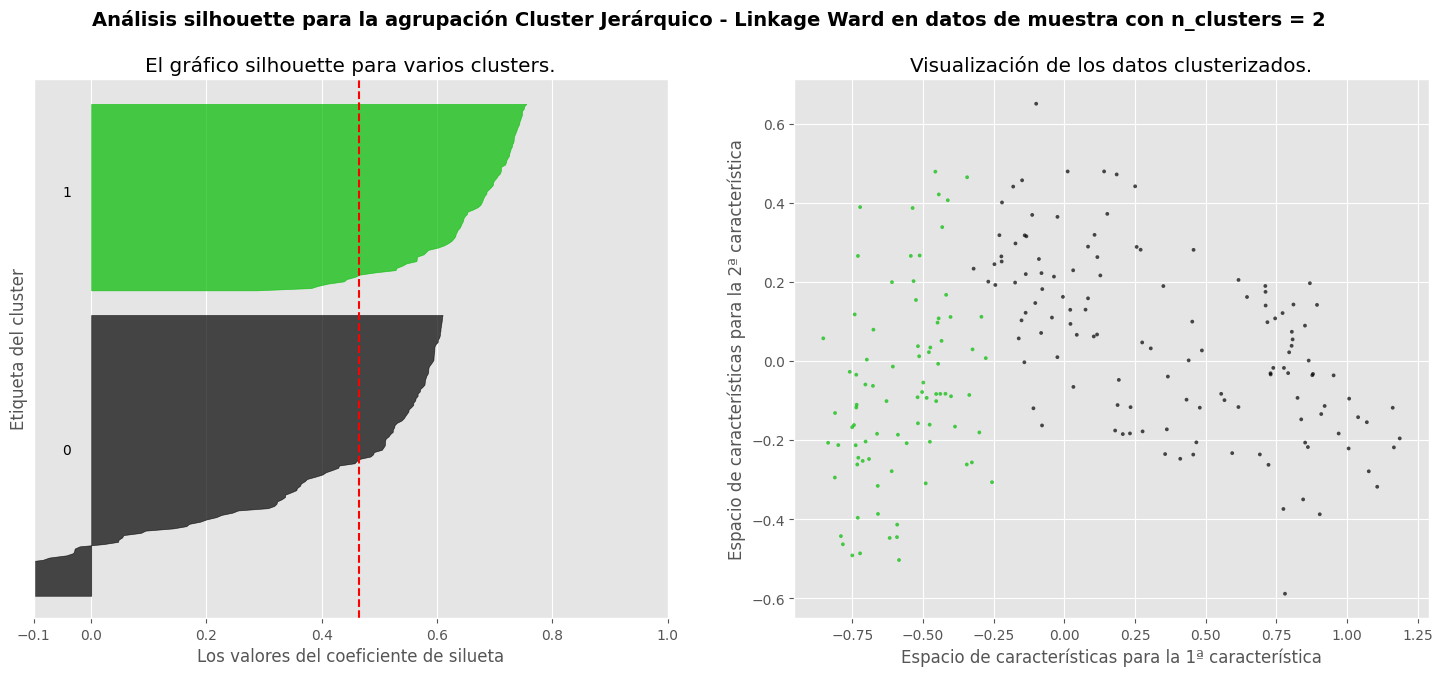

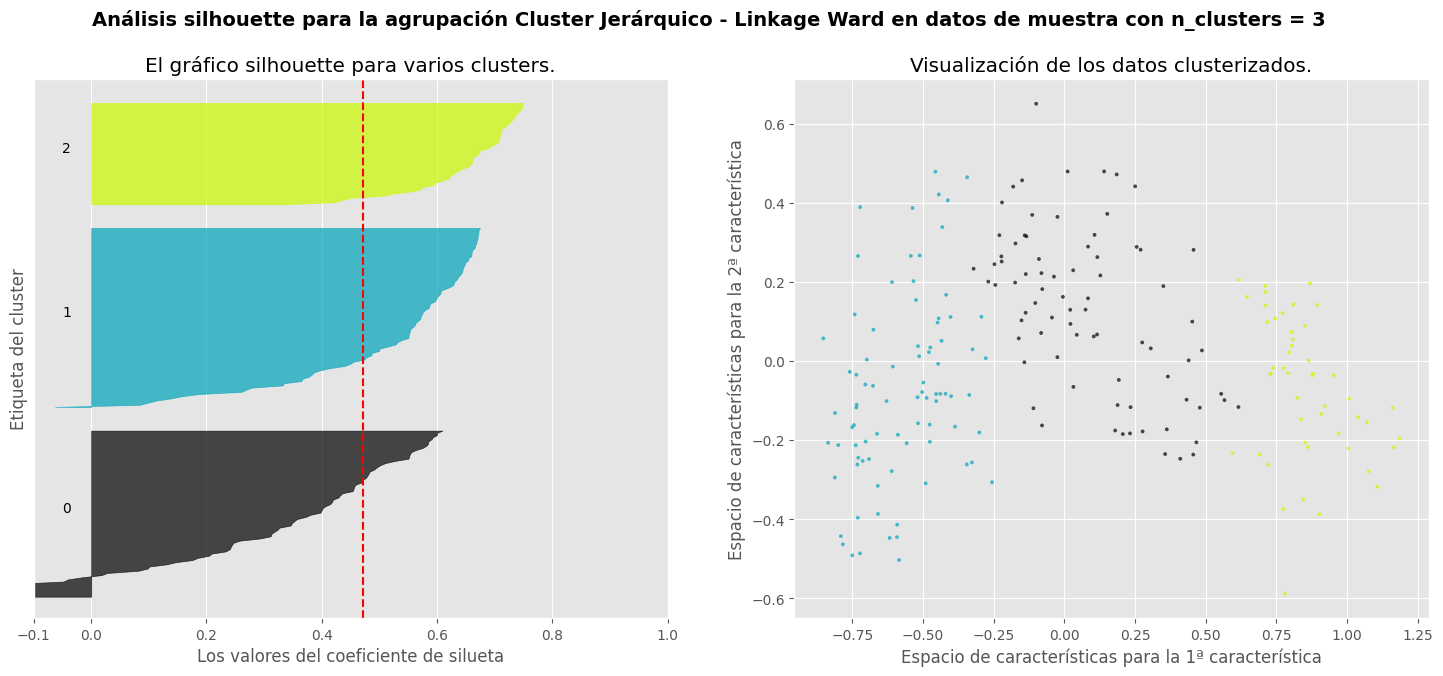

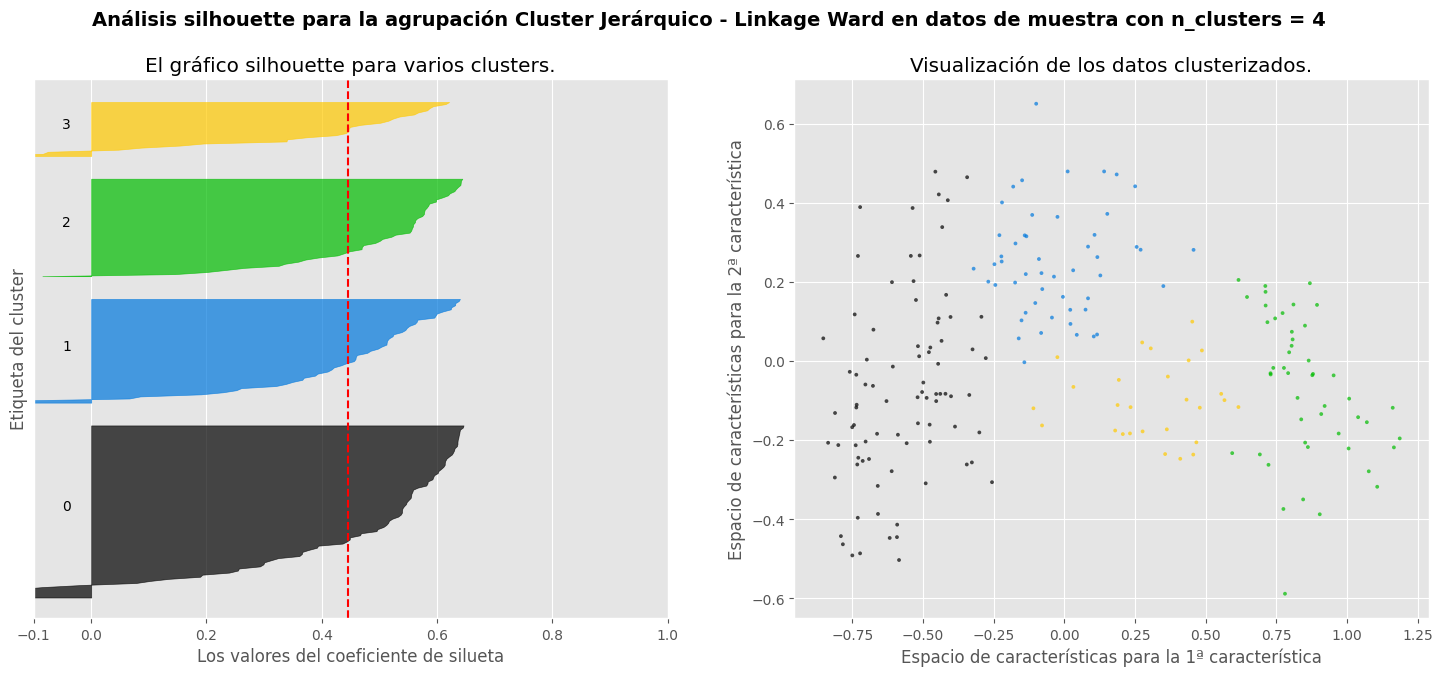

In [25]:
# Gráficos silhouette para identificar el número óptimo de clusters
# ==============================================================================

range_n_clusters = [2, 3, 4,]

for n_clusters in range_n_clusters:
    # Crear un subplot con 1 fila y dos columnas
    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    # El primer subplot es el gráfico silhouette
    # El coeficiente de silhouette puede oscilar entre -1, 1 pero en este ejemplo
    # todos se encuentran dentro de [-0.1, 1]
    ax1.set_xlim([-0.1, 1])
    # El (n_clusters+1)*10 sirve para insertar un espacio en blanco entre los
    # gráficos de silhouette de los clusters individuales, para delimitarlos claramente.
    ax1.set_ylim([0, len(X_minmax) + (n_clusters + 1) * 10])

    # Inicializar el clusterer con n_clusters valor y un generador aleatorio
    # aleatorio de 42 para la reproducibilidad.
    clusterer = AgglomerativeClustering(
        linkage    = 'ward',
        n_clusters = n_clusters
    )

    cluster_labels = clusterer.fit_predict(X_minmax)

    # El silhouette_score da el valor medio de todas las muestras. Esto da una
    # perspectiva de la densidad y separación de los clusters formados
    silhouette_avg = silhouette_score(X_minmax, cluster_labels)
    print(
        "Para n_clusters =",
        n_clusters,
        "La media de silhouette_score es :",
        silhouette_avg,
    )

    # Calcular las puntuaciones de silhouette de cada muestra
    sample_silhouette_values = silhouette_samples(X_minmax, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        # Agregar las puntuaciones de silhouette de las muestras pertenecientes al
        # cluster i, y ordénelas
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]

        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Etiquetar los gráficos de silhouette con sus números de cluster en el
        # centro.
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Calcular el nuevo y_lower para el siguiente gráfico
        y_lower = y_upper + 10

    ax1.set_title("El gráfico silhouette para varios clusters.")
    ax1.set_xlabel("Los valores del coeficiente de silueta")
    ax1.set_ylabel("Etiqueta del cluster")

    # La línea vertical para la puntuación media de silhouette de todos los valores
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([])
    ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    # El segundo plot dibuja los clusters formados
    colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
    ax2.scatter(
        X_minmax[:, 0], X_minmax[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k"
    )


    ax2.set_title("Visualización de los datos clusterizados.")
    ax2.set_xlabel("Espacio de características para la 1ª característica")
    ax2.set_ylabel("Espacio de características para la 2ª característica")

    plt.suptitle(
        "Análisis silhouette para la agrupación Cluster Jerárquico - Linkage Ward en datos de muestra con n_clusters = %d"
        % n_clusters,
        fontsize=14,
        fontweight="bold",
    )

plt.show()

Para el linkage complete el mejor resultado son 3 clusters y una media de 0.47

### Resultado:

Para los clusters jerárquicos el mejor resultado es usar una función linkage de tipo complete con k = 2 clusters.

In [26]:
modelo_final_hclust = modelo = AgglomerativeClustering(
        linkage    = 'complete',
        n_clusters = 2
    )
modelo_final_hclust.fit(X_minmax)

AgglomerativeClustering(linkage='complete')

## DBSCAN

Para este caso usaremos un modelo base con una distancia entre muestras de 0.2, 5 muestras mínimas para considerar un core-point y como métrica para la distancia, la distancia euclidea.

Buscaremos ajustar los valores de eps y mínimo de muestras.

In [27]:
modelo_dbscan = DBSCAN(
    eps          = 0.2,
    min_samples  = 5,
    metric       = 'euclidean',
)

modelo_dbscan.fit(X=X_minmax)

DBSCAN(eps=0.2)

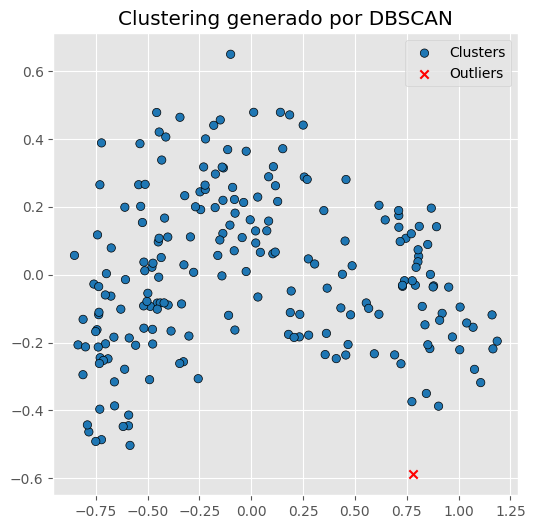

In [28]:
# Etiquetas de clusters generadas por DBSCAN
labels = modelo_dbscan.labels_

fig, ax = plt.subplots(1, 1, figsize=(6, 6))

# Puntos normales
ax.scatter(
    x = X_minmax[labels != -1, 0],
    y = X_minmax[labels != -1, 1],
    c = labels[labels != -1],
    cmap = 'tab10',
    marker = 'o',
    edgecolor = 'black',
    label = 'Clusters'
)

# Puntos outliers (label == -1)
ax.scatter(
    x = X_minmax[labels == -1, 0],
    y = X_minmax[labels == -1, 1],
    c = 'red',
    marker = 'x',
    edgecolor = 'black',
    label = 'Outliers'
)

ax.legend()
ax.set_title('Clustering generado por DBSCAN')
plt.grid(True)
plt.show()

Como podemos ver, el modelo base solo clasifica un cluster, así que hay que ajustar los valores de min_samples y eps.

Para ajustar los valores se calculará el silhouette_score descartando aquellos valores cuyos clusters genereados estén desequilibrados:

In [29]:
param_grid = {
    'eps': np.linspace(0.1, 2.0, 200),
    'min_samples': range(3, 20),
    'metric': ['euclidean', 'l1', 'l2', 'manhattan', 'cosine']
}

best_score = -1
best_params = None
min_entropy = 1.0 

for params in ParameterGrid(param_grid):
    db = DBSCAN(eps=params['eps'], min_samples=params['min_samples'], metric=params['metric']).fit(X_minmax)
    labels = db.labels_

    # Filtrar ruido y contar instancias por cluster
    cluster_counts = Counter(labels)
    if -1 in cluster_counts:
        del cluster_counts[-1]
    
    n_clusters = len(cluster_counts)

    if n_clusters > 1:
        counts = np.array(list(cluster_counts.values()))
        proportions = counts / counts.sum()
        balance_entropy = entropy(proportions)

        # Verifica si los clusters están balanceados
        if balance_entropy >= min_entropy:
            score = silhouette_score(X_minmax, labels)
            if score > best_score:
                best_score = score
                best_params = params

print("Mejores parámetros:", best_params)
print("Mejor silhouette score:", best_score)

Mejores parámetros: {'eps': np.float64(0.1477386934673367), 'metric': 'euclidean', 'min_samples': 13}
Mejor silhouette score: 0.32246788120051667


Ajustamos el modelo base con los nuevos valores:

In [30]:
modelo_dbscan = DBSCAN(
    eps          = 0.1477,
    min_samples  = 13,
    metric       = 'euclidean',
)

modelo_dbscan.fit(X=X_minmax)

DBSCAN(eps=0.1477, min_samples=13)

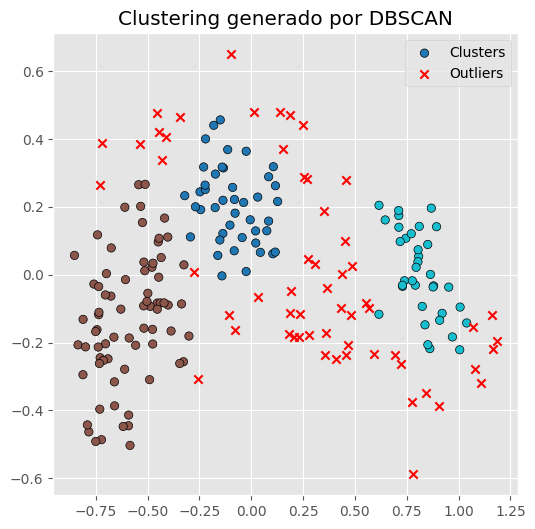

In [31]:
# Etiquetas de clusters generadas por DBSCAN
labels = modelo_dbscan.labels_

fig, ax = plt.subplots(1, 1, figsize=(6, 6))

# Puntos normales
ax.scatter(
    x = X_minmax[labels != -1, 0],
    y = X_minmax[labels != -1, 1],
    c = labels[labels != -1],
    cmap = 'tab10',
    marker = 'o',
    edgecolor = 'black',
    label = 'Clusters'
)

# Puntos outliers (label == -1)
ax.scatter(
    x = X_minmax[labels == -1, 0],
    y = X_minmax[labels == -1, 1],
    c = 'red',
    marker = 'x',
    edgecolor = 'black',
    label = 'Outliers'
)

ax.legend()
ax.set_title('Clustering generado por DBSCAN')
plt.grid(True)
plt.show()

### Resultado:

Habiendo obtenido unos clusters equilibrados, el valor de silhouette_score es bajo (0.32) y el número de outliers es bastante alto, sin embargo no tener en cuenta el equilibrio de los clusters puede dar un score mayor y un menor número de outliers lo que puede implicar sobreaprendizaje. 

# Análisis de los resultados:

## Comparación de los diferentes clusters

* K-Means:

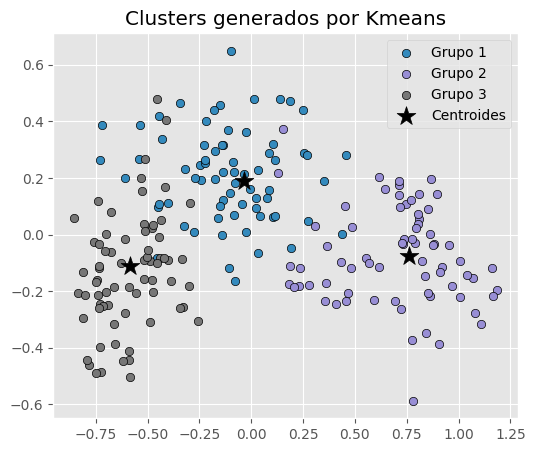

In [32]:
y_predict = modelo_kmeans_final.predict(X=X_minmax)
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
for i in np.unique(y):
    ax.scatter(
        x = X_minmax[y == i, 0],
        y = X_minmax[y == i, 1],
        c = plt.rcParams['axes.prop_cycle'].by_key()['color'][i],
        marker    = 'o',
        edgecolor = 'black',
        label= f"Grupo {i}"
    )

ax.scatter(
    x = modelo_kmeans_final.cluster_centers_[:, 0],
    y = modelo_kmeans_final.cluster_centers_[:, 1],
    c = 'black',
    s = 200,
    marker = '*',
    label  = 'Centroides'
)
ax.set_title('Clusters generados por Kmeans')
ax.legend();

* Hierarchical Clustering

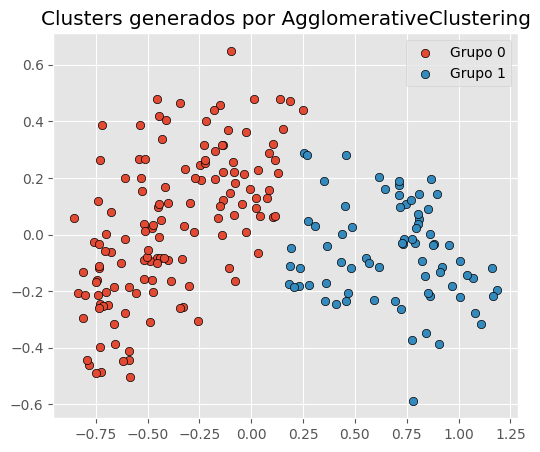

In [33]:
y_predict = modelo_final_hclust.labels_
fig, ax = plt.subplots(1, 1, figsize=(6, 5))

for i in np.unique(y_predict):
    ax.scatter(
        x = X_minmax[y_predict == i, 0],
        y = X_minmax[y_predict == i, 1],
        c = plt.rcParams['axes.prop_cycle'].by_key()['color'][i],
        marker = 'o',
        edgecolor = 'black',
        label = f"Grupo {i}"
    )

ax.set_title('Clusters generados por AgglomerativeClustering')
ax.legend()
plt.show()

* DBSCAN

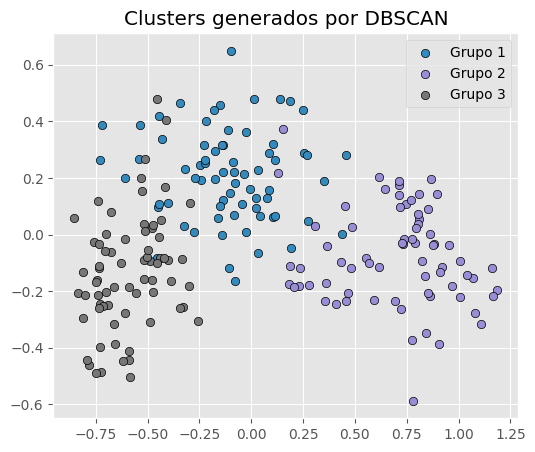

In [34]:
y_predict = modelo_dbscan.labels_
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
for i in np.unique(y):
    ax.scatter(
        x = X_minmax[y == i, 0],
        y = X_minmax[y == i, 1],
        c = plt.rcParams['axes.prop_cycle'].by_key()['color'][i],
        marker    = 'o',
        edgecolor = 'black',
        label= f"Grupo {i}"
    )

ax.set_title('Clusters generados por DBSCAN')
ax.legend();

Como podemos ver tanto K-Means como DBSCAN generan 3 clusters, siendo ambos resultados muy similares, mientras que Hierarchical Clustering solo lo hace con 2.

Si lo comparamos con los datos originales (columna de clase), podemos ver que los que más se acercan son K-Means y DBSCAN, ya que, hay 3 clases de semillas, por lo que a partir de ahora solo compararemos estos dos tipos.

## Interpretación de los clusters

Vamos a usar boxplots para explicar los resultados de los modelos que más se acercan al número de clases real.

### Comparación por variable

In [35]:
# 1. Crear DataFrame con tus datos originales
df_original = datos.copy()
df_original.drop('clase', axis=1, inplace=True)

# 2. Añadir los clusters
df_original['Cluster_KMeans'] = modelo_kmeans_final.labels_
df_original['Cluster_DBSCAN'] = modelo_dbscan.labels_

# 3. Lista de variables (excluyendo los Clusters)
variables = df_original.columns.drop(['Cluster_KMeans', 'Cluster_DBSCAN'])

n_cols = 4

* K-Means:

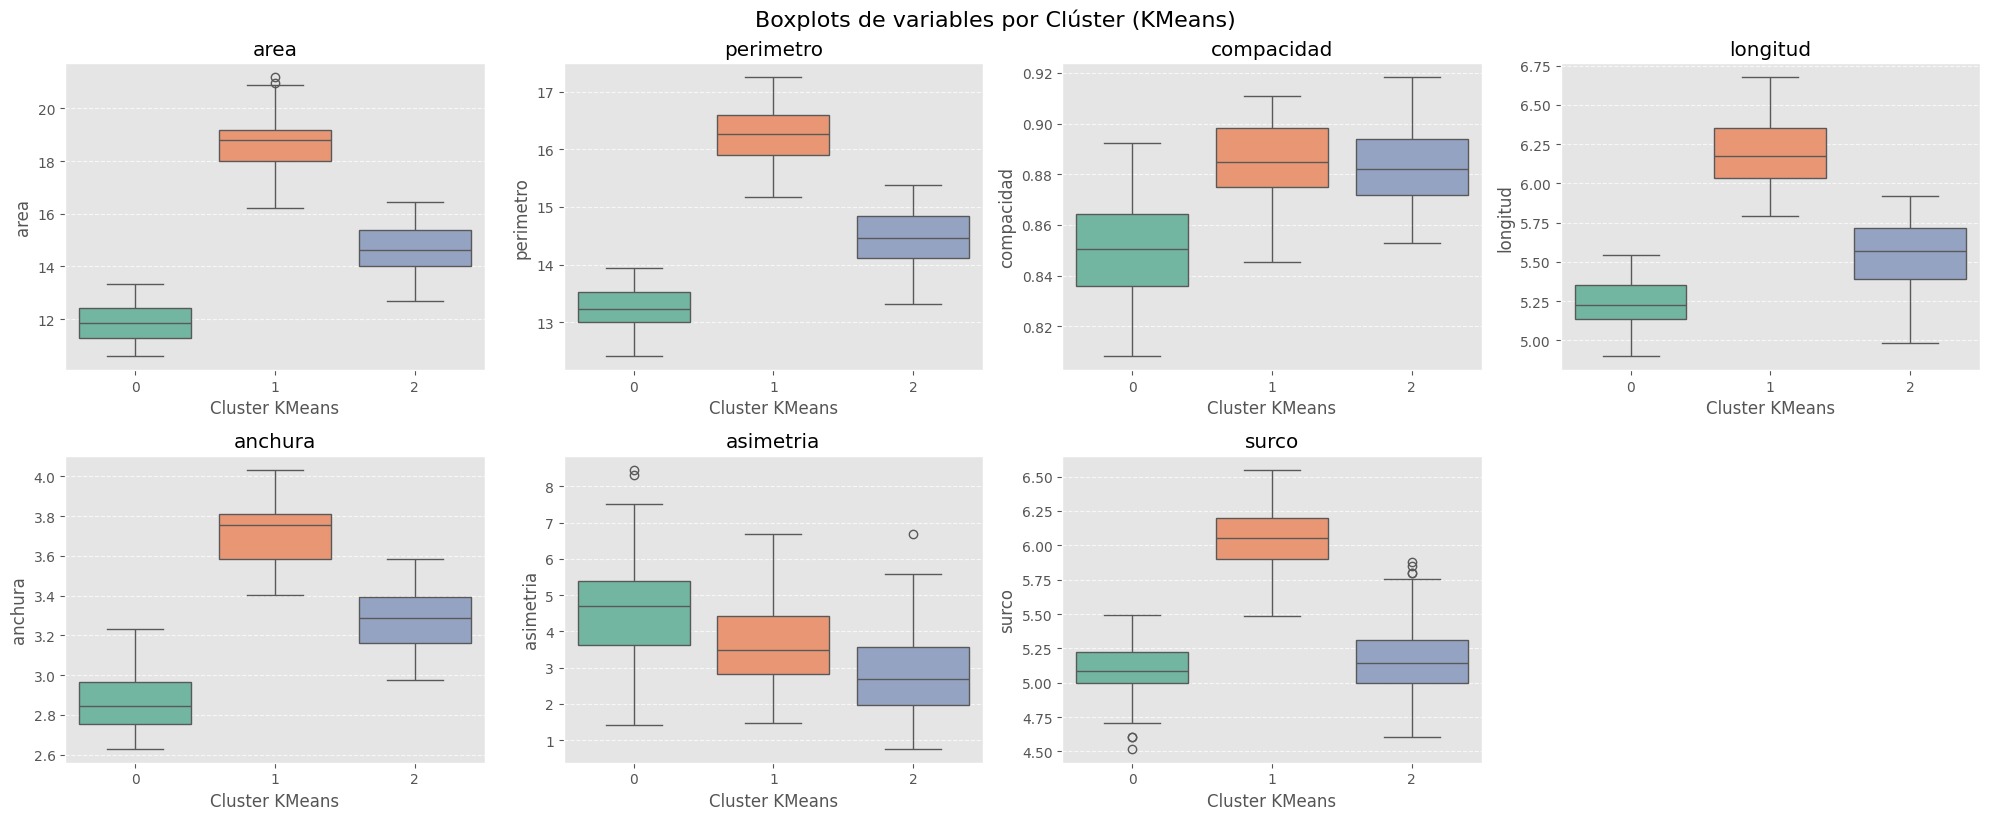

In [36]:
n_rows = math.ceil(len(variables) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))

axes = axes.flatten()

for idx, var in enumerate(variables):
    sns.boxplot(x='Cluster_KMeans', y=var, data=df_original, ax=axes[idx], palette="Set2")
    axes[idx].set_title(f'{var}')
    axes[idx].set_xlabel('Cluster KMeans')
    axes[idx].grid(axis='y', linestyle='--', alpha=0.7)

# Si sobran espacios, los apagamos
for idx in range(len(variables), len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.suptitle("Boxplots de variables por Clúster (KMeans)", y=1.02, fontsize=16)
plt.show()

* DBSCAN:

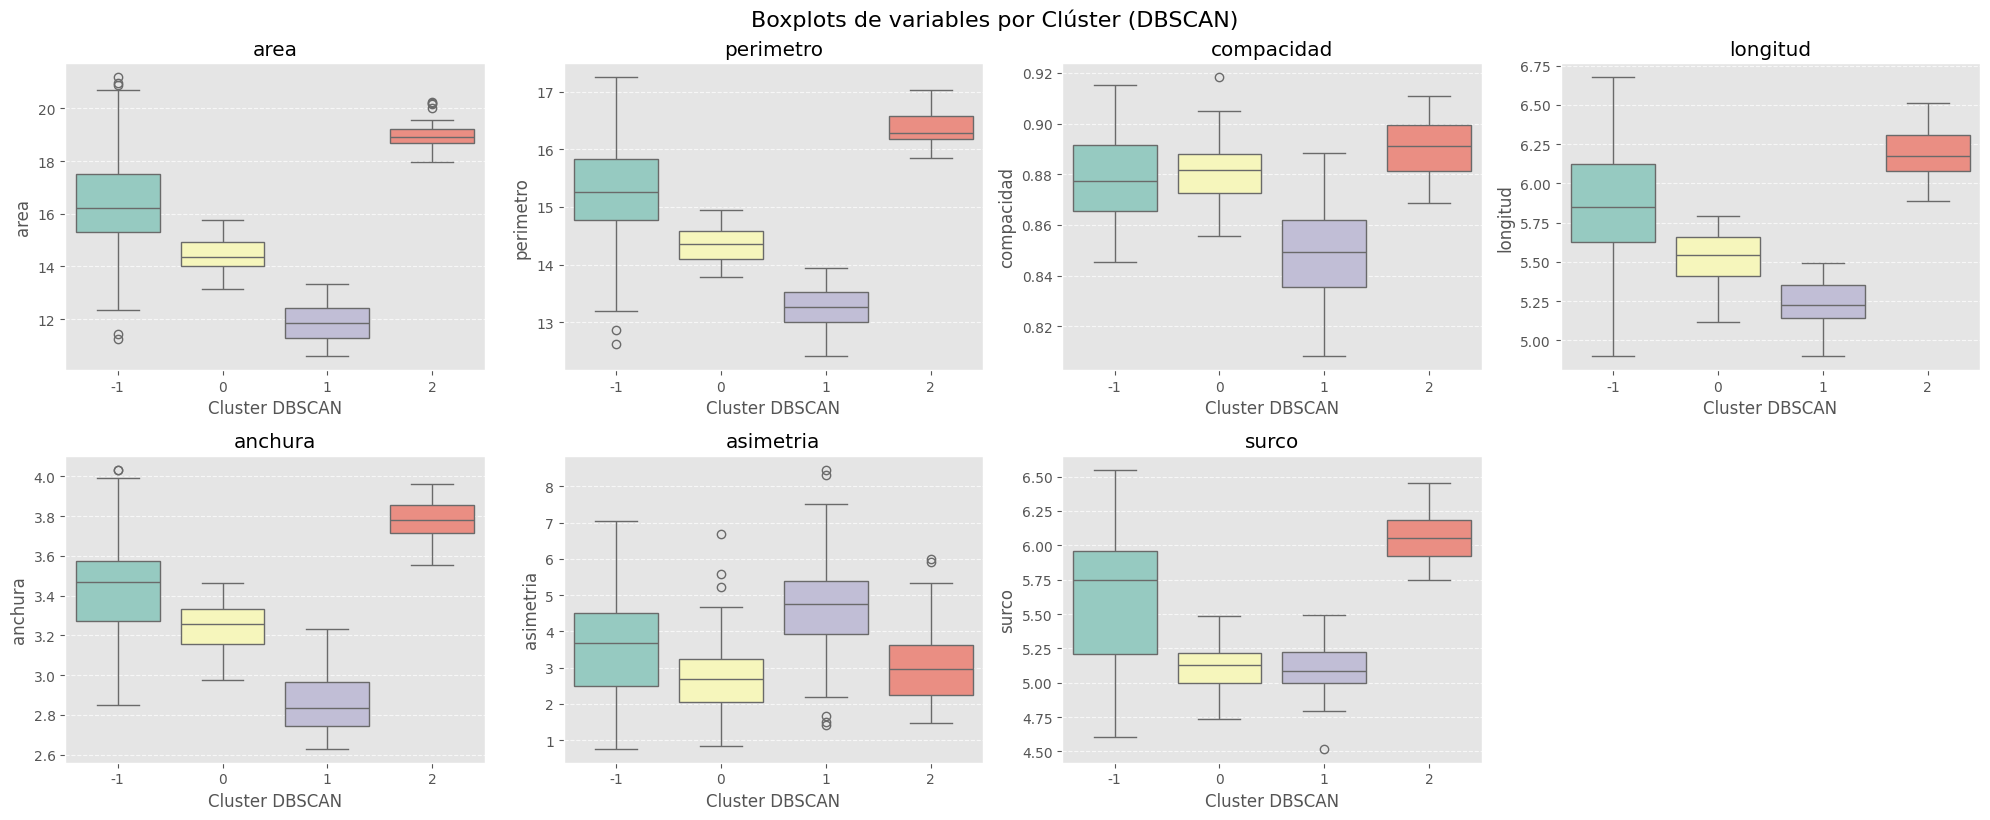

In [37]:
n_rows = math.ceil(len(variables) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))

axes = axes.flatten()

for idx, var in enumerate(variables):
    sns.boxplot(x='Cluster_DBSCAN', y=var, data=df_original, ax=axes[idx], palette="Set3")
    axes[idx].set_title(f'{var}')
    axes[idx].set_xlabel('Cluster DBSCAN')
    axes[idx].grid(axis='y', linestyle='--', alpha=0.7)

# Si sobran espacios, los apagamos
for idx in range(len(variables), len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.suptitle("Boxplots de variables por Clúster (DBSCAN)", y=1.02, fontsize=16)
plt.show()

La principal diferencia entre ambos modelos es la capacidad de ***DBSCAN*** para detectar outliers, cosa que ***K-Means*** no puede hacer. 

Por otro lado, ***DBSCAN*** presenta una mayor cantidad de outliers en las variables "***area***", "***compacidad***" y "***asimetría***", mientras que ***K-Means*** presenta una mayor cantidad en la variable "***surco***", esto se debe al comportamiendo de ***DBSCAN*** y la capacidad de formar clusters con formas menos estrictas en comparación a ***K-Means***.

También podemos ver que la distribución interna de los clusters, a nivel general, es más compacta en el caso de ***DBSCAN*** que en ***K-Means***, por otro lado, en ambos casos podemos ver una variabilidad general de la mediana, lo que indica que los clusters son diferentes, aunque en el caso de la variable "***compacidad***" de ***K-Means*** y "***surco***" de ***DBSCAN*** hay clusters muy cercanos.

Por último, en el caso de ***DBSCAN*** los boxplots son más esrechos, indicando que los clusters son más compactos.


Por todo esto se podría decir que, en este caso, ***DBSCAN*** ha agrupado mejor los datos.